In [1]:
import os
import math
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

SEED = 2026
def seed_everything(s=SEED):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = "/kaggle/input/datasets/subhajit9876/afhq-v2-64x64"
WORK_DIR = "/kaggle/working"
BATCH_SIZE = 64

# Load saved numpy arrays
X_train_np = np.load(os.path.join(DATA_ROOT, "train_images.npy"))
y_train_np = np.load(os.path.join(DATA_ROOT, "train_labels.npy"))
X_val_np = np.load(os.path.join(DATA_ROOT, "val_images.npy"))
y_val_np = np.load(os.path.join(DATA_ROOT, "val_labels.npy"))

def prepare_images(x):
    return (
        torch.from_numpy(x)
        .permute(0, 3, 1, 2)
        .contiguous()
        .float()
        .div_(127.5)
        .sub_(1.0)
    )

X_train = prepare_images(X_train_np)
X_val = prepare_images(X_val_np)
y_train = torch.from_numpy(y_train_np).long()
y_val = torch.from_numpy(y_val_np).long()

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

def get_val_class_sample(cls_label, rel_idx):
    """Fetch deterministic sample by class index (0=cat, 1=dog, 2=wild)."""
    cls_positions = torch.nonzero(y_val == cls_label, as_tuple=False).squeeze(1)
    global_idx = cls_positions[rel_idx].item()
    return X_val[global_idx], y_val[global_idx], global_idx

print(f"Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Range: [{X_train.min().item():.2f}, {X_train.max().item():.2f}]")

Device: cuda (Tesla T4)
Train: torch.Size([14336, 3, 64, 64]), Val: torch.Size([1467, 3, 64, 64]), Range: [-1.00, 1.00]


## Phase 1: Denoising Diffusion Probabilistic Models (AFHQ-v2)

### 1.1 The Forward Process & Noise Schedules
Given a data sample $x_0 \sim q(x_0)$, the forward Markovian diffusion process gradually corrupts the image over $T = 1000$ discrete steps according to a variance schedule $\{\beta_t\}_{t=1}^T$:

$$q(x_t \mid x_{t-1}) = \mathcal{N}\left(x_t;\, \sqrt{1 - \beta_t}\, x_{t-1},\, \beta_t \mathbf{I}\right)$$

Defining $\alpha_t = 1 - \beta_t$ and the cumulative signal product $\bar{\alpha}_t = \prod_{s=1}^t \alpha_s$, the closed-form marginal distribution at arbitrary timestep $t$ is:

$$q(x_t \mid x_0) = \mathcal{N}\left(x_t;\, \sqrt{\bar{\alpha}_t}\, x_0,\, (1 - \bar{\alpha}_t)\mathbf{I}\right) \implies x_t = \sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1 - \bar{\alpha}_t}\,\epsilon, \quad \epsilon \sim \mathcal{N}(0, \mathbf{I})$$

* **Linear Schedule:** $\beta_t$ increases linearly from $\beta_1 = 10^{-4}$ to $\beta_T = 0.02$.
* **Cosine Schedule (Nichol & Dhariwal, 2021):** Constructed via the cumulative schedule with offset $s = 0.008$:
  $$f(t) = \cos^2\left(\frac{t/T + s}{1 + s} \cdot \frac{\pi}{2}\right), \quad \bar{\alpha}_t = \frac{f(t)}{f(0)}, \quad \beta_t = \text{clip}\left(1 - \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}},\, 0,\, 0.999\right)$$
* **Log-SNR & Forward Posterior:** The Signal-to-Noise Ratio is $\text{SNR}(t) = \frac{\bar{\alpha}_t}{1 - \bar{\alpha}_t}$. Conditioned on $x_0$, the tractable reverse posterior is $q(x_{t-1} \mid x_t, x_0) = \mathcal{N}(x_{t-1};\, \tilde{\mu}_t(x_t, x_0),\, \tilde{\beta}_t \mathbf{I})$, where:
  $$\tilde{\mu}_t(x_t, x_0) = \frac{\sqrt{\bar{\alpha}_{t-1}}\beta_t}{1 - \bar{\alpha}_t} x_0 + \frac{\sqrt{\alpha_t}(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t} x_t, \qquad \tilde{\beta}_t = \frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t} \beta_t$$

<>:52: SyntaxWarning: invalid escape sequence '\m'
<>:52: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_59/4021979847.py:52: SyntaxWarning: invalid escape sequence '\m'
  """Closed-form posterior q(x_{t-1} | x_t, x_0) = N(\tilde{\mu}_t, \tilde{\beta}_t I)."""


Linear \bar{\alpha}_T (t=1000)         : 4.03582962e-05
Cosine \bar{\alpha}_T (t=1000)         : 2.42876697e-09
Cosine log SNR(500) [0-indexed idx=500] : -0.030862
Cosine log SNR(500) [1-indexed idx=499] : -0.024627


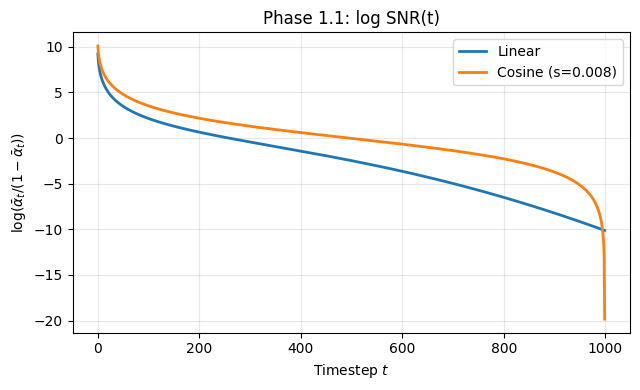

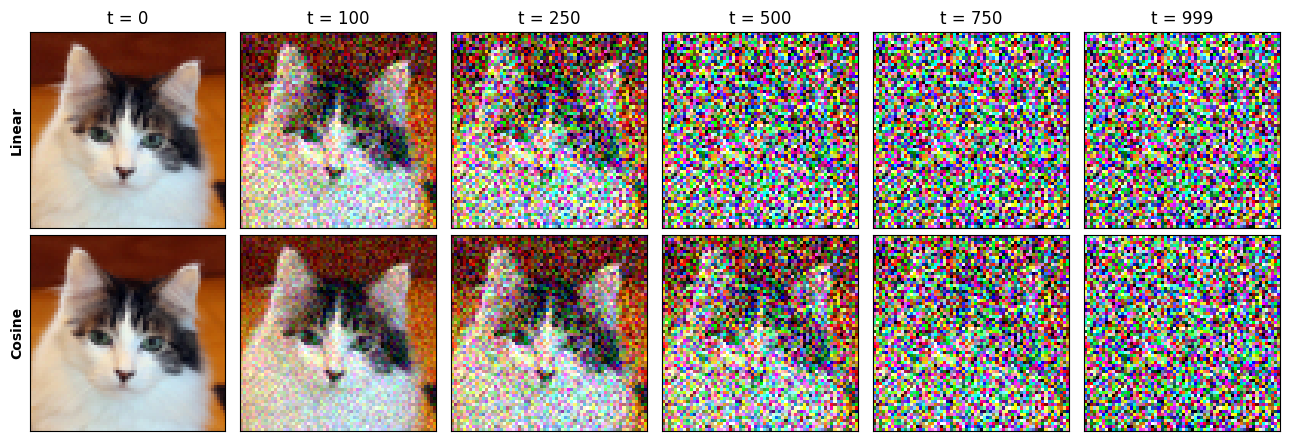

In [2]:
class DiffusionSchedule:
    def __init__(self, schedule_type="cosine", T=1000, beta_1=1e-4, beta_T=0.02, s=0.008, device="cpu"):
        self.schedule_type = schedule_type
        self.T = T
        self.device = device

        if schedule_type == "linear":
            betas = torch.linspace(beta_1, beta_T, T, dtype=torch.float64)
        elif schedule_type == "cosine":
            steps = torch.arange(T + 1, dtype=torch.float64)
            f_t = torch.cos(((steps / T + s) / (1.0 + s)) * (math.pi * 0.5)) ** 2
            alphas_cumprod_full = f_t / f_t[0]
            betas = 1.0 - (alphas_cumprod_full[1:] / alphas_cumprod_full[:-1])
            betas = torch.clamp(betas, min=0.0, max=0.999)
        else:
            raise ValueError(f"Unknown schedule_type: {schedule_type}")

        alphas = 1.0 - betas
        alphas_cumprod = torch.cumprod(alphas, dim=0)
        alphas_cumprod_prev = torch.cat([torch.tensor([1.0], dtype=torch.float64), alphas_cumprod[:-1]], dim=0)

        # Posterior q(x_{t-1} | x_t, x_0) = N(\tilde{\mu}_t, \tilde{\beta}_t I)
        posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)
        posterior_mean_coef1 = betas * torch.sqrt(alphas_cumprod_prev) / (1.0 - alphas_cumprod)
        posterior_mean_coef2 = (1.0 - alphas_cumprod_prev) * torch.sqrt(alphas) / (1.0 - alphas_cumprod)

        self.betas = betas.float().to(device)
        self.alphas = alphas.float().to(device)
        self.alphas_cumprod = alphas_cumprod.float().to(device)
        self.alphas_cumprod_prev = alphas_cumprod_prev.float().to(device)

        self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - self.alphas_cumprod)

        self.posterior_variance = posterior_variance.float().to(device)
        self.posterior_mean_coef1 = posterior_mean_coef1.float().to(device)
        self.posterior_mean_coef2 = posterior_mean_coef2.float().to(device)

    def _extract(self, a, t, x_shape):
        out = a.gather(0, t)
        return out.view(t.shape[0], *((1,) * (len(x_shape) - 1)))

    def q_sample(self, x_0, t, noise=None, generator=None):
        """Closed-form forward sampler q(x_t | x_0)."""
        if noise is None:
            noise = torch.randn(x_0.shape, device=x_0.device, dtype=x_0.dtype, generator=generator)
        sqrt_ab = self._extract(self.sqrt_alphas_cumprod, t, x_0.shape)
        sqrt_one_minus_ab = self._extract(self.sqrt_one_minus_alphas_cumprod, t, x_0.shape)
        return sqrt_ab * x_0 + sqrt_one_minus_ab * noise

    def q_posterior(self, x_0, x_t, t):
        """Closed-form posterior q(x_{t-1} | x_t, x_0) = N(\tilde{\mu}_t, \tilde{\beta}_t I)."""
        coef1 = self._extract(self.posterior_mean_coef1, t, x_t.shape)
        coef2 = self._extract(self.posterior_mean_coef2, t, x_t.shape)
        tilde_mu = coef1 * x_0 + coef2 * x_t
        tilde_beta = self._extract(self.posterior_variance, t, x_t.shape)
        return tilde_mu, tilde_beta

    def log_snr(self):
        return torch.log(self.alphas_cumprod / (1.0 - self.alphas_cumprod))


T_STEPS = 1000
sched_linear = DiffusionSchedule("linear", T=T_STEPS, device=device)
sched_cosine = DiffusionSchedule("cosine", T=T_STEPS, device=device)

log_snr_linear = sched_linear.log_snr().cpu().numpy()
log_snr_cosine = sched_cosine.log_snr().cpu().numpy()

print(f"Linear \\bar{{\\alpha}}_T (t=1000)         : {sched_linear.alphas_cumprod[-1].item():.8e}")
print(f"Cosine \\bar{{\\alpha}}_T (t=1000)         : {sched_cosine.alphas_cumprod[-1].item():.8e}")
print(f"Cosine log SNR(500) [0-indexed idx=500] : {log_snr_cosine[500]:.6f}")
print(f"Cosine log SNR(500) [1-indexed idx=499] : {log_snr_cosine[499]:.6f}")

# Plot 1: log SNR(t)
plt.figure(figsize=(6.5, 4))
t_axis = np.arange(T_STEPS)
plt.plot(t_axis, log_snr_linear, label="Linear", lw=2)
plt.plot(t_axis, log_snr_cosine, label="Cosine (s=0.008)", lw=2)
plt.xlabel("Timestep $t$")
plt.ylabel(r"$\log(\bar{\alpha}_t / (1 - \bar{\alpha}_t))$")
plt.title("Phase 1.1: log SNR(t)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 2: Noised AFHQ-v2 image at t in {0, 100, 250, 500, 750, 999}
x0_vis = X_val[0:1].to(device)
t_list = [0, 100, 250, 500, 750, 999]

fig, axes = plt.subplots(2, 6, figsize=(13, 4.5))
for r, (name, sched) in enumerate([("Linear", sched_linear), ("Cosine", sched_cosine)]):
    gen = torch.Generator(device=device).manual_seed(SEED)
    eps = torch.randn(x0_vis.shape, device=device, generator=gen)
    for c, t_val in enumerate(t_list):
        t_tensor = torch.tensor([t_val], device=device, dtype=torch.long)
        xt = sched.q_sample(x0_vis, t_tensor, noise=eps)
        img = np.clip((xt[0].cpu().permute(1, 2, 0).numpy() + 1.0) * 0.5, 0.0, 1.0)
        axes[r, c].imshow(img)
        if r == 0:
            axes[r, c].set_title(f"t = {t_val}")
        if c == 0:
            axes[r, c].set_ylabel(name, fontweight="bold")
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
plt.tight_layout()
plt.show()

### 1.2 Parameterizations, Shared Conditional U-Net & Classifier-Free Training

#### 1. Prediction Parameterizations ($\epsilon$, $x_0$, $v$)
Given $x_t = \sqrt{\bar{\alpha}_t}\,x_0 + \sqrt{1 - \bar{\alpha}_t}\,\epsilon$, the velocity target is defined as $v_t = \sqrt{\bar{\alpha}_t}\,\epsilon - \sqrt{1 - \bar{\alpha}_t}\,x_0$. Any single prediction linearly determines the other two:

$$\hat{x}_0 = \frac{x_t - \sqrt{1 - \bar{\alpha}_t}\,\hat{\epsilon}}{\sqrt{\bar{\alpha}_t}} = \sqrt{\bar{\alpha}_t}\,x_t - \sqrt{1 - \bar{\alpha}_t}\,\hat{v}, \qquad \hat{\epsilon} = \frac{x_t - \sqrt{\bar{\alpha}_t}\,\hat{x}_0}{\sqrt{1 - \bar{\alpha}_t}} = \sqrt{1 - \bar{\alpha}_t}\,x_t + \sqrt{\bar{\alpha}_t}\,\hat{v}$$

#### 2. Shared Conditional U-Net & Residual Block Architecture
Time $t$ is encoded via a $d$-dimensional sinusoidal embedding $\gamma(t) \in \mathbb{R}^{64}$ mapped through a 2-layer SiLU MLP to $\mathbb{R}^{256}$, and summed with a learned class embedding $e(y) \in \mathbb{R}^{256}$ (with $K+1$ entries to include the null token $\emptyset$):

```text
  [ SHARED CONDITIONAL U-NET (64x64 -> 8x8 -> 64x64) ]                [ FiLM RESIDUAL BLOCK ]
                                                                             x_in
  x_t (3x64x64) ──► Conv3x3 (64) ─────────────────────────►(+)──► Out         │
                       │                                    ▲                 ├──────────────────┐
                   [64x64, 64ch]  ResBlock x2 ──(skip)─────►│                 ▼                  │
                       │ Downsample                         │          GroupNorm + SiLU          │
                   [32x32, 128ch] ResBlock x2 ──(skip)─────►│                 │                  │
                       │ Downsample                         │              Conv3x3               │
                   [16x16, 192ch] (ResBlock + SelfAttn) x2 ►│                 │                  │
                       │ Downsample                         │      t_emb + c_emb ──► Linear      │
                    [8x8, 256ch]  (ResBlock + SelfAttn) x2 ►│                 │    (scale, shift)│
                       │                                    │                 ▼                  │
                   Bottleneck: ResBlock ──► SelfAttn ──► ResBlock     GroupNorm * (1+s) + b      │
                                                                              │                  │
                                                                      SiLU + Dropout + Conv3x3   │
                                                                              │                  │
                                                                             (+)◄── 1x1 Skip ────┘
                                                                              ▼
                                                                            x_out

In [3]:
# =====================================================================
# 1. Parameterization Targets & Linear Conversion Maps (eps, x0, v)
# =====================================================================
class ParameterizationConverter:
    def __init__(self, schedule: DiffusionSchedule):
        self.sched = schedule

    def _coeffs(self, t, x_shape):
        a = self.sched._extract(self.sched.sqrt_alphas_cumprod, t, x_shape)
        s = self.sched._extract(self.sched.sqrt_one_minus_alphas_cumprod, t, x_shape)
        return a, s

    # Targets from (x_0, eps)
    def get_v_target(self, x_0, eps, t):
        a, s = self._coeffs(t, x_0.shape)
        return a * eps - s * x_0

    # Pairwise conversions given noisy state x_t = a * x_0 + s * eps
    def eps_to_x0(self, x_t, eps, t):
        a, s = self._coeffs(t, x_t.shape)
        return (x_t - s * eps) / a

    def x0_to_eps(self, x_t, x_0, t):
        a, s = self._coeffs(t, x_t.shape)
        return (x_t - a * x_0) / s

    def eps_to_v(self, x_t, eps, t):
        a, s = self._coeffs(t, x_t.shape)
        x_0 = self.eps_to_x0(x_t, eps, t)
        return a * eps - s * x_0

    def v_to_eps(self, x_t, v, t):
        a, s = self._coeffs(t, x_t.shape)
        return s * x_t + a * v

    def v_to_x0(self, x_t, v, t):
        a, s = self._coeffs(t, x_t.shape)
        return a * x_t - s * v

    def x0_to_v(self, x_t, x_0, t):
        a, s = self._coeffs(t, x_t.shape)
        eps = self.x0_to_eps(x_t, x_0, t)
        return a * eps - s * x_0


# Numerical verification on a random batch with dedicated Generator (seed=2026)
converter = ParameterizationConverter(sched_cosine)
gen_verify = torch.Generator(device=device).manual_seed(SEED)

x0_batch = X_train[:BATCH_SIZE].to(device)
t_batch = torch.randint(0, T_STEPS, (BATCH_SIZE,), device=device, generator=gen_verify)
eps_batch = torch.randn(x0_batch.shape, device=device, generator=gen_verify)

xt_batch = sched_cosine.q_sample(x0_batch, t_batch, noise=eps_batch)
v_target = converter.get_v_target(x0_batch, eps_batch, t_batch)

# Round-trip: eps -> v -> eps
v_from_eps = converter.eps_to_v(xt_batch, eps_batch, t_batch)
eps_roundtrip = converter.v_to_eps(xt_batch, v_from_eps, t_batch)
max_abs_err_eps_v_eps = (eps_batch - eps_roundtrip).abs().max().item()

# Also check all other conversions for completeness
x0_from_eps = converter.eps_to_x0(xt_batch, eps_batch, t_batch)
x0_from_v = converter.v_to_x0(xt_batch, v_from_eps, t_batch)
max_abs_err_x0 = (x0_batch - x0_from_v).abs().max().item()

print(f"Max absolute round-trip error (eps -> v -> eps) : {max_abs_err_eps_v_eps:.8e}")
print(f"Max absolute reconstruction error (x0 vs v->x0): {max_abs_err_x0:.8e}")


# =====================================================================
# 2. Shared Backbone: Sinusoidal Embedding + Conditional U-Net
# =====================================================================
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        # t: 1D tensor of shape (B,), supports both integer steps and continuous float t
        half_dim = self.dim // 2
        emb_scale = math.log(10000.0) / (half_dim - 1)
        freqs = torch.exp(torch.arange(half_dim, device=t.device, dtype=torch.float32) * (-emb_scale))
        args = t.float().unsqueeze(1) * freqs.unsqueeze(0)
        emb = torch.cat([torch.sin(args), torch.cos(args)], dim=-1)
        if self.dim % 2 == 1:
            emb = F.pad(emb, (0, 1))
        return emb


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, emb_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(32 if in_ch >= 32 else in_ch, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
        self.emb_proj = nn.Linear(emb_dim, out_ch * 2)
        self.norm2 = nn.GroupNorm(32 if out_ch >= 32 else out_ch, out_ch)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, kernel_size=1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.emb_proj(F.silu(emb)).chunk(2, dim=-1)
        h = self.norm2(h) * (1.0 + scale[:, :, None, None]) + shift[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(h)))
        return h + self.skip(x)


class SelfAttentionBlock(nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()
        self.num_heads = num_heads
        self.norm = nn.GroupNorm(32 if channels >= 32 else channels, channels)
        self.qkv = nn.Conv2d(channels, channels * 3, kernel_size=1)
        self.proj = nn.Conv2d(channels, channels, kernel_size=1)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)
        qkv = self.qkv(h).view(B, 3, self.num_heads, C // self.num_heads, H * W)
        q, k, v = qkv[:, 0], qkv[:, 1], qkv[:, 2]  # each: (B, heads, head_dim, HW)
        q = q.permute(0, 1, 3, 2)  # (B, heads, HW, head_dim)
        k = k.permute(0, 1, 3, 2)
        v = v.permute(0, 1, 3, 2)
        attn_out = F.scaled_dot_product_attention(q, k, v)  # (B, heads, HW, head_dim)
        attn_out = attn_out.permute(0, 1, 3, 2).reshape(B, C, H, W)
        return x + self.proj(attn_out)


class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2.0, mode="nearest")
        return self.conv(x)


class SharedUNet(nn.Module):
    """
    Shared U-Net Backbone across Phases 1, 2, 3, 4.
    - Num classes = K; Null token \emptyset is assigned index K (total K + 1 embeddings).
    """
    def __init__(
        self,
        in_channels=3,
        out_channels=3,
        base_ch=64,
        ch_mults=(1, 2, 3, 4),
        num_res_blocks=2,
        attn_levels=(2, 3),
        num_classes=3,
        dropout=0.1,
    ):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.num_classes = num_classes
        self.null_class_idx = num_classes

        emb_dim = base_ch * 4
        self.sinusoidal_emb = SinusoidalTimeEmbedding(base_ch)
        self.time_mlp = nn.Sequential(
            nn.Linear(base_ch, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )
        # Class embedding table with +1 entry for null token \emptyset
        self.class_emb = nn.Embedding(num_classes + 1, emb_dim)

        self.in_conv = nn.Conv2d(in_channels, base_ch, kernel_size=3, padding=1)

        # Downsampling path
        self.down_blocks = nn.ModuleList()
        self.down_attns = nn.ModuleList()
        self.downsamples = nn.ModuleList()

        curr_ch = base_ch
        skip_channels = [curr_ch]
        num_levels = len(ch_mults)

        for level in range(num_levels):
            out_ch = base_ch * ch_mults[level]
            level_res = nn.ModuleList()
            level_attn = nn.ModuleList()
            for _ in range(num_res_blocks):
                level_res.append(ResBlock(curr_ch, out_ch, emb_dim, dropout))
                curr_ch = out_ch
                level_attn.append(SelfAttentionBlock(curr_ch) if level in attn_levels else nn.Identity())
                skip_channels.append(curr_ch)
            self.down_blocks.append(level_res)
            self.down_attns.append(level_attn)

            if level != num_levels - 1:
                self.downsamples.append(Downsample(curr_ch))
                skip_channels.append(curr_ch)
            else:
                self.downsamples.append(nn.Identity())

        # Bottleneck at lowest resolution
        self.mid_block1 = ResBlock(curr_ch, curr_ch, emb_dim, dropout)
        self.mid_attn = SelfAttentionBlock(curr_ch)
        self.mid_block2 = ResBlock(curr_ch, curr_ch, emb_dim, dropout)

        # Upsampling path
        self.up_blocks = nn.ModuleList()
        self.up_attns = nn.ModuleList()
        self.upsamples = nn.ModuleList()

        for level in reversed(range(num_levels)):
            out_ch = base_ch * ch_mults[level]
            level_res = nn.ModuleList()
            level_attn = nn.ModuleList()
            for _ in range(num_res_blocks + 1):
                skip_ch = skip_channels.pop()
                level_res.append(ResBlock(curr_ch + skip_ch, out_ch, emb_dim, dropout))
                curr_ch = out_ch
                level_attn.append(SelfAttentionBlock(curr_ch) if level in attn_levels else nn.Identity())
            self.up_blocks.append(level_res)
            self.up_attns.append(level_attn)

            if level != 0:
                self.upsamples.append(Upsample(curr_ch))
            else:
                self.upsamples.append(nn.Identity())

        self.out_norm = nn.GroupNorm(32 if curr_ch >= 32 else curr_ch, curr_ch)
        self.out_conv = nn.Conv2d(curr_ch, out_channels, kernel_size=3, padding=1)
        nn.init.zeros_(self.out_conv.weight)
        nn.init.zeros_(self.out_conv.bias)

    def forward(self, x, t, y=None):
        if y is None:
            y = torch.full((x.shape[0],), self.null_class_idx, device=x.device, dtype=torch.long)

        t_emb = self.time_mlp(self.sinusoidal_emb(t))
        c_emb = self.class_emb(y)
        emb = t_emb + c_emb

        h = self.in_conv(x)
        skips = [h]

        for level in range(len(self.down_blocks)):
            for res, attn in zip(self.down_blocks[level], self.down_attns[level]):
                h = attn(res(h, emb))
                skips.append(h)
            if not isinstance(self.downsamples[level], nn.Identity):
                h = self.downsamples[level](h)
                skips.append(h)

        h = self.mid_block2(self.mid_attn(self.mid_block1(h, emb)), emb)

        for level in range(len(self.up_blocks)):
            for res, attn in zip(self.up_blocks[level], self.up_attns[level]):
                h = torch.cat([h, skips.pop()], dim=1)
                h = attn(res(h, emb))
            if not isinstance(self.upsamples[level], nn.Identity):
                h = self.upsamples[level](h)

        return self.out_conv(F.silu(self.out_norm(h)))


# Instantiate model with seed=2026 and report sinusoidal embedding L2 norms at t=0 and t=999
seed_everything(SEED)
model_afhq = SharedUNet(
    in_channels=3,
    out_channels=3,
    base_ch=64,
    ch_mults=(1, 2, 3, 4),
    num_res_blocks=2,
    attn_levels=(2, 3),
    num_classes=3,
    dropout=0.1,
).to(device)

t_test = torch.tensor([0, 999], device=device, dtype=torch.long)
sin_embs = model_afhq.sinusoidal_emb(t_test)
norm_t0 = torch.linalg.vector_norm(sin_embs[0], ord=2).item()
norm_t999 = torch.linalg.vector_norm(sin_embs[1], ord=2).item()

num_params = sum(p.numel() for p in model_afhq.parameters())
print(f"Sinusoidal embedding dim                       : {model_afhq.sinusoidal_emb.dim}")
print(f"L2 norm of sinusoidal embedding at t=0         : {norm_t0:.6f}")
print(f"L2 norm of sinusoidal embedding at t=999       : {norm_t999:.6f}")
print(f"SharedUNet total parameters                    : {num_params:,}")

<>:153: SyntaxWarning: invalid escape sequence '\e'
<>:153: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_59/3837276183.py:153: SyntaxWarning: invalid escape sequence '\e'
  - Num classes = K; Null token \emptyset is assigned index K (total K + 1 embeddings).


Max absolute round-trip error (eps -> v -> eps) : 9.53674316e-07
Max absolute reconstruction error (x0 vs v->x0): 5.04553318e-05
Sinusoidal embedding dim                       : 64
L2 norm of sinusoidal embedding at t=0         : 5.656854
L2 norm of sinusoidal embedding at t=999       : 5.656854
SharedUNet total parameters                    : 23,035,331


>>> [Deliverable] Training Loss at Epoch 1, Batch 1: 0.998539
Epoch [001/100] | Avg Loss: 0.21960 | Time: 123.6s
Epoch [002/100] | Avg Loss: 0.07169 | Time: 122.6s
Epoch [003/100] | Avg Loss: 0.06510 | Time: 122.8s
Epoch [004/100] | Avg Loss: 0.06331 | Time: 122.4s
Epoch [005/100] | Avg Loss: 0.06213 | Time: 122.7s
Epoch [006/100] | Avg Loss: 0.05969 | Time: 122.8s
Epoch [007/100] | Avg Loss: 0.05850 | Time: 122.8s
Epoch [008/100] | Avg Loss: 0.05791 | Time: 122.8s
Epoch [009/100] | Avg Loss: 0.05522 | Time: 122.8s
Epoch [010/100] | Avg Loss: 0.05625 | Time: 122.9s [Checkpoint Saved]


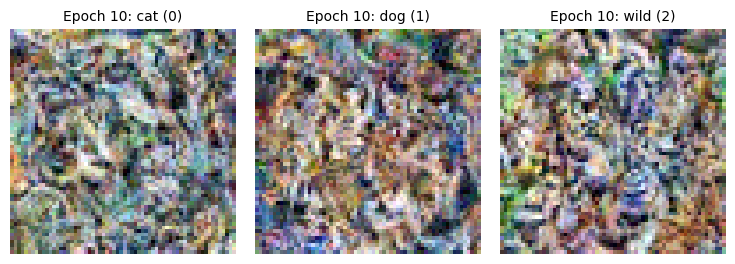

Epoch [011/100] | Avg Loss: 0.05597 | Time: 122.9s
Epoch [012/100] | Avg Loss: 0.05462 | Time: 123.1s
Epoch [013/100] | Avg Loss: 0.05592 | Time: 123.1s
Epoch [014/100] | Avg Loss: 0.05419 | Time: 123.1s
Epoch [015/100] | Avg Loss: 0.05588 | Time: 123.2s
Epoch [016/100] | Avg Loss: 0.05516 | Time: 123.2s
Epoch [017/100] | Avg Loss: 0.05307 | Time: 123.1s
Epoch [018/100] | Avg Loss: 0.05384 | Time: 123.2s
Epoch [019/100] | Avg Loss: 0.05380 | Time: 123.2s
Epoch [020/100] | Avg Loss: 0.05332 | Time: 123.1s [Checkpoint Saved]


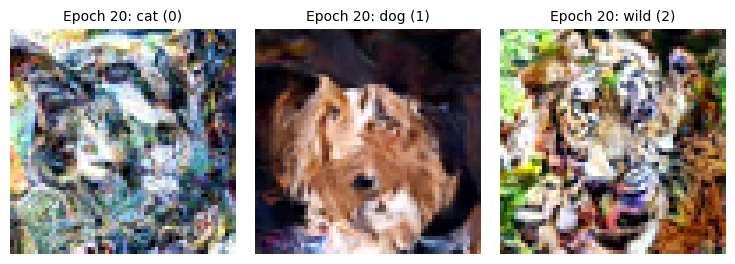

Epoch [021/100] | Avg Loss: 0.05390 | Time: 123.5s
Epoch [022/100] | Avg Loss: 0.05300 | Time: 123.3s
Epoch [023/100] | Avg Loss: 0.05356 | Time: 123.1s
Epoch [024/100] | Avg Loss: 0.05415 | Time: 123.1s
Epoch [025/100] | Avg Loss: 0.05314 | Time: 123.0s
Epoch [026/100] | Avg Loss: 0.05349 | Time: 123.1s
Epoch [027/100] | Avg Loss: 0.05221 | Time: 123.1s
Epoch [028/100] | Avg Loss: 0.05375 | Time: 123.2s
Epoch [029/100] | Avg Loss: 0.05228 | Time: 123.2s
Epoch [030/100] | Avg Loss: 0.05228 | Time: 123.3s [Checkpoint Saved]


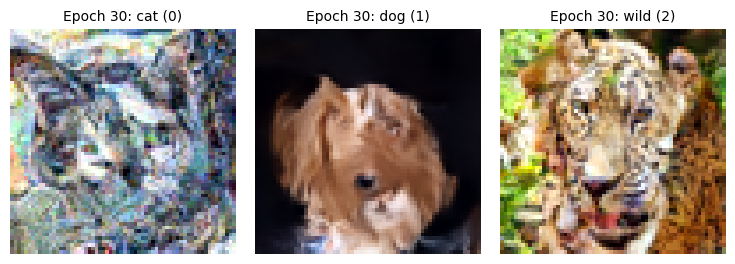

Epoch [031/100] | Avg Loss: 0.05232 | Time: 123.3s
Epoch [032/100] | Avg Loss: 0.05234 | Time: 123.5s
Epoch [033/100] | Avg Loss: 0.05267 | Time: 123.5s
Epoch [034/100] | Avg Loss: 0.05266 | Time: 123.6s
Epoch [035/100] | Avg Loss: 0.05080 | Time: 123.5s
Epoch [036/100] | Avg Loss: 0.05203 | Time: 123.4s
Epoch [037/100] | Avg Loss: 0.05269 | Time: 123.4s
Epoch [038/100] | Avg Loss: 0.05258 | Time: 123.5s
Epoch [039/100] | Avg Loss: 0.05194 | Time: 123.5s
Epoch [040/100] | Avg Loss: 0.05154 | Time: 123.5s [Checkpoint Saved]


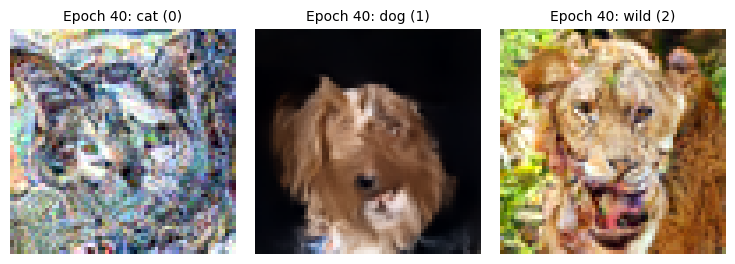

Epoch [041/100] | Avg Loss: 0.05091 | Time: 123.4s
Epoch [042/100] | Avg Loss: 0.05197 | Time: 123.5s
Epoch [043/100] | Avg Loss: 0.05058 | Time: 123.5s
Epoch [044/100] | Avg Loss: 0.05071 | Time: 123.5s
Epoch [045/100] | Avg Loss: 0.05157 | Time: 123.6s
Epoch [046/100] | Avg Loss: 0.05183 | Time: 123.6s
Epoch [047/100] | Avg Loss: 0.05140 | Time: 123.6s
Epoch [048/100] | Avg Loss: 0.05282 | Time: 123.6s
Epoch [049/100] | Avg Loss: 0.05013 | Time: 123.6s
Epoch [050/100] | Avg Loss: 0.05186 | Time: 123.7s [Checkpoint Saved]


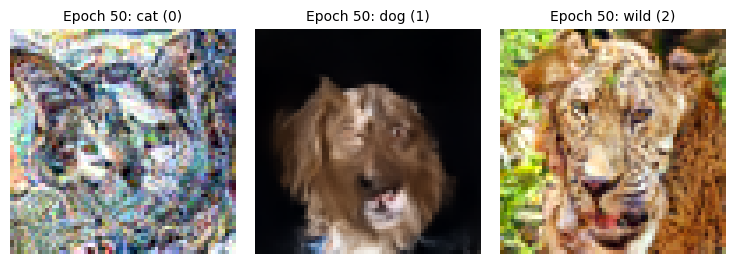

Epoch [051/100] | Avg Loss: 0.05157 | Time: 123.7s
Epoch [052/100] | Avg Loss: 0.05147 | Time: 123.7s
Epoch [053/100] | Avg Loss: 0.05052 | Time: 123.7s
Epoch [054/100] | Avg Loss: 0.05071 | Time: 123.7s
Epoch [055/100] | Avg Loss: 0.05129 | Time: 123.7s
Epoch [056/100] | Avg Loss: 0.05068 | Time: 123.6s
Epoch [057/100] | Avg Loss: 0.05236 | Time: 123.7s
Epoch [058/100] | Avg Loss: 0.05093 | Time: 123.8s
Epoch [059/100] | Avg Loss: 0.05083 | Time: 123.8s
Epoch [060/100] | Avg Loss: 0.04975 | Time: 123.7s [Checkpoint Saved]


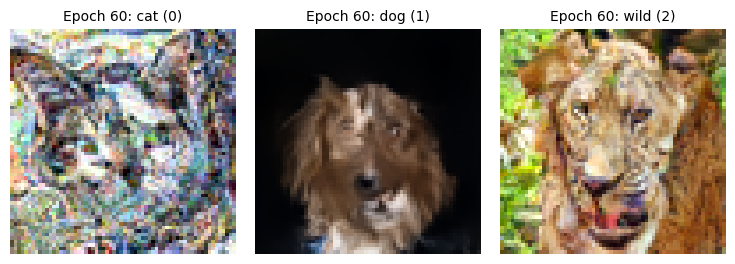

Epoch [061/100] | Avg Loss: 0.05097 | Time: 123.7s
Epoch [062/100] | Avg Loss: 0.05079 | Time: 123.4s
Epoch [063/100] | Avg Loss: 0.04945 | Time: 123.4s
Epoch [064/100] | Avg Loss: 0.05107 | Time: 123.3s
Epoch [065/100] | Avg Loss: 0.05028 | Time: 123.4s
Epoch [066/100] | Avg Loss: 0.04987 | Time: 123.5s
Epoch [067/100] | Avg Loss: 0.04989 | Time: 123.4s
Epoch [068/100] | Avg Loss: 0.05060 | Time: 123.4s
Epoch [069/100] | Avg Loss: 0.05045 | Time: 123.3s
Epoch [070/100] | Avg Loss: 0.05029 | Time: 123.3s [Checkpoint Saved]


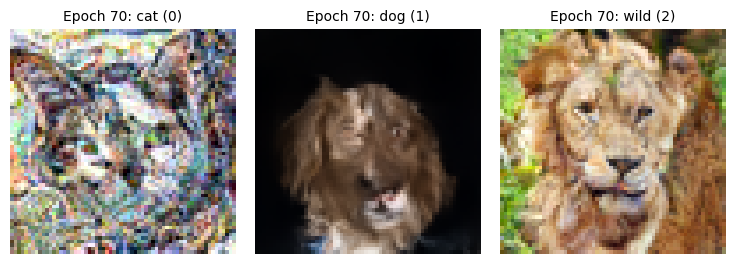

Epoch [071/100] | Avg Loss: 0.04999 | Time: 123.5s
Epoch [072/100] | Avg Loss: 0.05086 | Time: 123.7s
Epoch [073/100] | Avg Loss: 0.05147 | Time: 123.8s
Epoch [074/100] | Avg Loss: 0.05036 | Time: 123.8s
Epoch [075/100] | Avg Loss: 0.05044 | Time: 123.8s
Epoch [076/100] | Avg Loss: 0.05016 | Time: 123.8s
Epoch [077/100] | Avg Loss: 0.05001 | Time: 123.9s
Epoch [078/100] | Avg Loss: 0.04994 | Time: 123.9s
Epoch [079/100] | Avg Loss: 0.05082 | Time: 123.9s
Epoch [080/100] | Avg Loss: 0.04851 | Time: 123.7s [Checkpoint Saved]


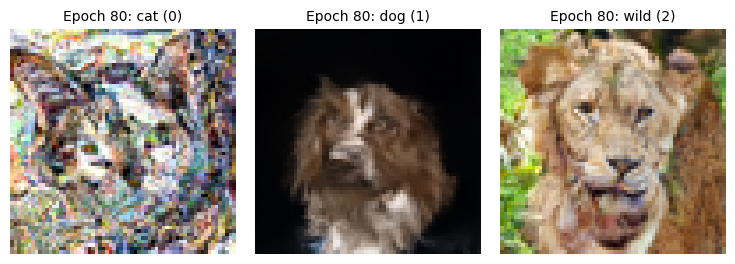

Epoch [081/100] | Avg Loss: 0.04968 | Time: 123.2s
Epoch [082/100] | Avg Loss: 0.04977 | Time: 123.2s
Epoch [083/100] | Avg Loss: 0.04993 | Time: 123.3s
Epoch [084/100] | Avg Loss: 0.04947 | Time: 123.3s
Epoch [085/100] | Avg Loss: 0.04962 | Time: 123.3s
Epoch [086/100] | Avg Loss: 0.05059 | Time: 123.3s
Epoch [087/100] | Avg Loss: 0.04978 | Time: 123.2s
Epoch [088/100] | Avg Loss: 0.04994 | Time: 123.3s
Epoch [089/100] | Avg Loss: 0.04871 | Time: 123.4s
Epoch [090/100] | Avg Loss: 0.04978 | Time: 123.4s [Checkpoint Saved]


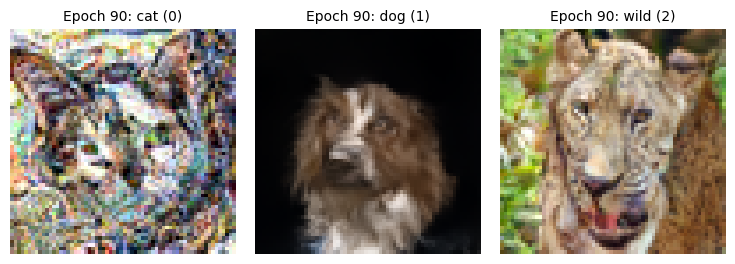

Epoch [091/100] | Avg Loss: 0.04949 | Time: 123.5s
Epoch [092/100] | Avg Loss: 0.04916 | Time: 123.7s
Epoch [093/100] | Avg Loss: 0.05080 | Time: 123.5s
Epoch [094/100] | Avg Loss: 0.04998 | Time: 123.4s
Epoch [095/100] | Avg Loss: 0.04924 | Time: 123.5s
Epoch [096/100] | Avg Loss: 0.04995 | Time: 123.4s
Epoch [097/100] | Avg Loss: 0.04987 | Time: 123.5s
Epoch [098/100] | Avg Loss: 0.04991 | Time: 123.4s
Epoch [099/100] | Avg Loss: 0.04998 | Time: 123.5s
Epoch [100/100] | Avg Loss: 0.04875 | Time: 123.5s [Checkpoint Saved]


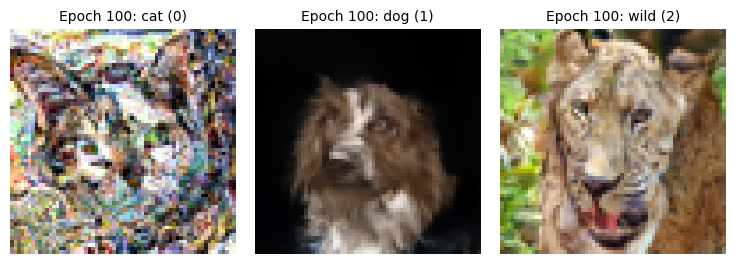


=== Phase 1.2 Training Deliverables ===
Training Loss at Epoch 1, Batch 1 : 0.998539
Final Epoch (100) Avg Loss      : 0.048746


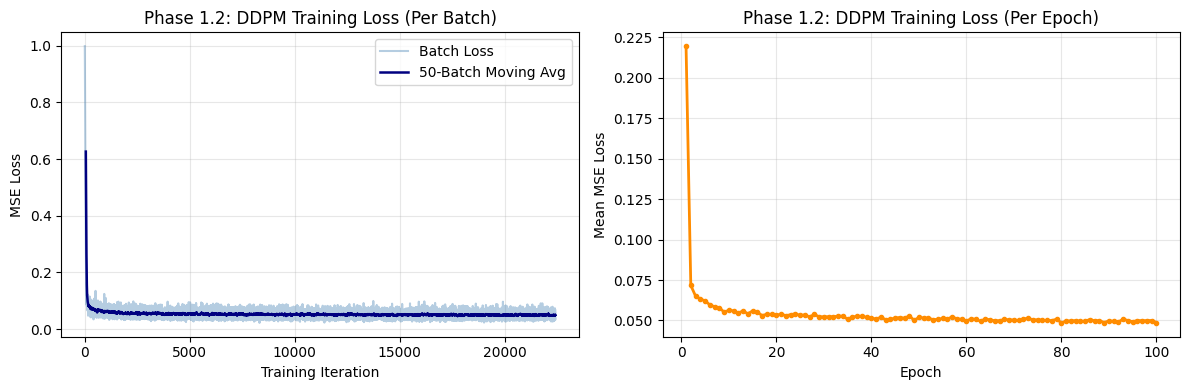

In [12]:
import copy
import time

torch.backends.cudnn.benchmark = True

class EMA:
    """Fast GPU-resident Exponential Moving Average."""
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.ema_model = copy.deepcopy(model).eval()
        for p in self.ema_model.parameters():
            p.requires_grad_(False)
        self.ema_params = list(self.ema_model.parameters())

    @torch.no_grad()
    def update(self, model):
        model_params = list(model.parameters())
        torch._foreach_lerp_(self.ema_params, model_params, 1.0 - self.decay)


@torch.no_grad()
def preview_samples(ema_net, sched, epoch, steps=50):
    """Quick 50-step deterministic DDIM preview (1 cat, 1 dog, 1 wild) every 10 epochs."""
    ema_net.eval()
    gen = torch.Generator(device=device).manual_seed(SEED)
    labels = torch.tensor([0, 1, 2], device=device, dtype=torch.long)  # cat, dog, wild
    x = torch.randn((3, 3, 64, 64), device=device, generator=gen)

    # Uniformly spaced subsequence of length `steps`
    tau = torch.linspace(0, sched.T - 1, steps, dtype=torch.long, device=device)
    for i in reversed(range(steps)):
        t_curr = tau[i]
        t_batch = torch.full((3,), t_curr, device=device, dtype=torch.long)
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            eps_pred = ema_net(x, t_batch, labels)

        ab_t = sched.alphas_cumprod[t_curr]
        ab_prev = sched.alphas_cumprod[tau[i - 1]] if i > 0 else torch.tensor(1.0, device=device)

        x0_pred = ((x - torch.sqrt(1.0 - ab_t) * eps_pred) / torch.sqrt(ab_t)).clamp(-1.0, 1.0)
        x = torch.sqrt(ab_prev) * x0_pred + torch.sqrt(1.0 - ab_prev) * eps_pred

    imgs = ((x.clamp(-1.0, 1.0) + 1.0) * 0.5).cpu().permute(0, 2, 3, 1).numpy()
    fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.6))
    for idx, cls_name in enumerate(["cat (0)", "dog (1)", "wild (2)"]):
        axes[idx].imshow(imgs[idx])
        axes[idx].set_title(f"Epoch {epoch}: {cls_name}", fontsize=10)
        axes[idx].axis("off")
    plt.tight_layout()
    plt.show()


# Re-initialize model cleanly with SEED=2026 so Epoch 1 Batch 1 is 100% deterministic
seed_everything(SEED)
model_afhq = SharedUNet(
    in_channels=3,
    out_channels=3,
    base_ch=64,
    ch_mults=(1, 2, 3, 4),
    num_res_blocks=2,
    attn_levels=(2, 3),
    num_classes=3,
    dropout=0.1,
).to(device)

EPOCHS = 100
LR = 2e-4
P_UNCOND = 0.10
NULL_TOKEN = 3
CKPT_PATH = os.path.join(WORK_DIR, "afhq_ddpm_ckpt.pt")

optimizer = torch.optim.AdamW(model_afhq.parameters(), lr=LR, weight_decay=1e-4)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_loader), eta_min=1e-5)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
ema = EMA(model_afhq, decay=0.999)

start_epoch = 1
batch_losses = []
epoch_losses = []
epoch1_batch1_loss = None

# Resume automatically if a saved 10-epoch checkpoint exists
if os.path.exists(CKPT_PATH):
    ckpt = torch.load(CKPT_PATH, map_location=device)
    model_afhq.load_state_dict(ckpt["model"])
    ema.ema_model.load_state_dict(ckpt["ema"])
    optimizer.load_state_dict(ckpt["optimizer"])
    lr_scheduler.load_state_dict(ckpt["lr_scheduler"])
    start_epoch = ckpt["epoch"] + 1
    batch_losses = ckpt["batch_losses"]
    epoch_losses = ckpt["epoch_losses"]
    epoch1_batch1_loss = ckpt["epoch1_batch1_loss"]
    print(f"Resumed from Epoch {ckpt['epoch']} (Epoch 1 Batch 1 Loss: {epoch1_batch1_loss:.6f})")

# Training Loop
for epoch in range(start_epoch, EPOCHS + 1):
    model_afhq.train()
    t0 = time.time()
    running_loss = 0.0

    for b_idx, (x0, y) in enumerate(train_loader, start=1):
        x0 = x0.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        B = x0.shape[0]

        # 10% label dropout to null token \emptyset (index 3)
        drop_mask = torch.rand(B, device=device) < P_UNCOND
        y_cond = torch.where(drop_mask, torch.full_like(y, NULL_TOKEN), y)

        # Sample random timesteps t in {0, ..., T-1} and Gaussian noise \epsilon
        t = torch.randint(0, T_STEPS, (B,), device=device, dtype=torch.long)
        eps = torch.randn_like(x0)
        xt = sched_cosine.q_sample(x0, t, noise=eps)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            eps_pred = model_afhq(xt, t, y_cond)
            loss = F.mse_loss(eps_pred, eps)

        if epoch == 1 and b_idx == 1:
            epoch1_batch1_loss = loss.item()
            print(f">>> [Deliverable] Training Loss at Epoch 1, Batch 1: {epoch1_batch1_loss:.6f}")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model_afhq.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        lr_scheduler.step()

        ema.update(model_afhq)

        loss_val = loss.item()
        batch_losses.append(loss_val)
        running_loss += loss_val

    avg_epoch_loss = running_loss / len(train_loader)
    epoch_losses.append(avg_epoch_loss)
    elapsed = time.time() - t0

    # Save checkpoint and plot sample preview ONLY every 10th epoch
    if epoch % 10 == 0 or epoch == EPOCHS:
        torch.save({
            "epoch": epoch,
            "model": model_afhq.state_dict(),
            "ema": ema.ema_model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "lr_scheduler": lr_scheduler.state_dict(),
            "batch_losses": batch_losses,
            "epoch_losses": epoch_losses,
            "epoch1_batch1_loss": epoch1_batch1_loss,
        }, CKPT_PATH)
        print(f"Epoch [{epoch:03d}/{EPOCHS:03d}] | Avg Loss: {avg_epoch_loss:.5f} | Time: {elapsed:.1f}s [Checkpoint Saved]")
        preview_samples(ema.ema_model, sched_cosine, epoch)
    else:
        print(f"Epoch [{epoch:03d}/{EPOCHS:03d}] | Avg Loss: {avg_epoch_loss:.5f} | Time: {elapsed:.1f}s")

eval_model = ema.ema_model.eval()

print(f"\n=== Phase 1.2 Training Deliverables ===")
print(f"Training Loss at Epoch 1, Batch 1 : {epoch1_batch1_loss:.6f}")
print(f"Final Epoch ({EPOCHS}) Avg Loss      : {epoch_losses[-1]:.6f}")

# Plot Training Loss Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(batch_losses, alpha=0.4, color="steelblue", label="Batch Loss")
if len(batch_losses) >= 50:
    smooth = np.convolve(batch_losses, np.ones(50)/50, mode="valid")
    axes[0].plot(range(49, len(batch_losses)), smooth, color="navy", lw=1.8, label="50-Batch Moving Avg")
axes[0].set_xlabel("Training Iteration")
axes[0].set_ylabel("MSE Loss")
axes[0].set_title("Phase 1.2: DDPM Training Loss (Per Batch)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, len(epoch_losses) + 1), epoch_losses, marker="o", color="darkorange", lw=2, markersize=3)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean MSE Loss")
axes[1].set_title("Phase 1.2: DDPM Training Loss (Per Epoch)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_58/4220509171.py:18: SyntaxWarning: invalid escape sequence '\s'
  - var_type: 'beta' (\sigma_t^2 = \beta_t) or 'tilde_beta' (\sigma_t^2 = \tilde{\beta}_t)


=== Phase 1.3 Reported Deliverables ===
Mean pixel value (dog, sigma_t^2 = beta_t)       [-1, 1] scale : -0.437754  | [0, 1] scale: 0.281123
Mean pixel value (dog, sigma_t^2 = tilde_beta_t) [-1, 1] scale : -0.437896  | [0, 1] scale: 0.281052


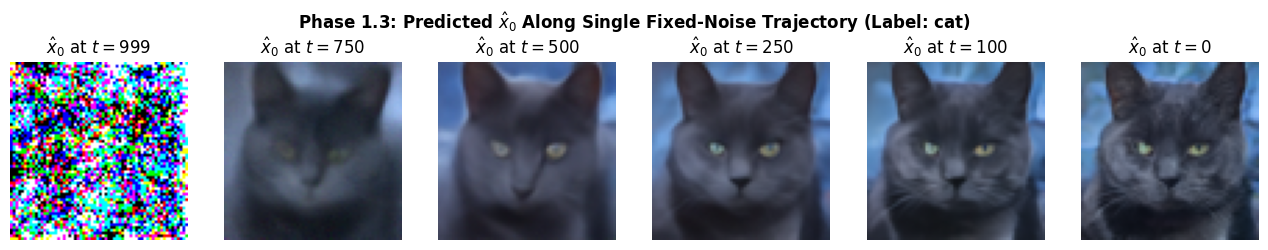

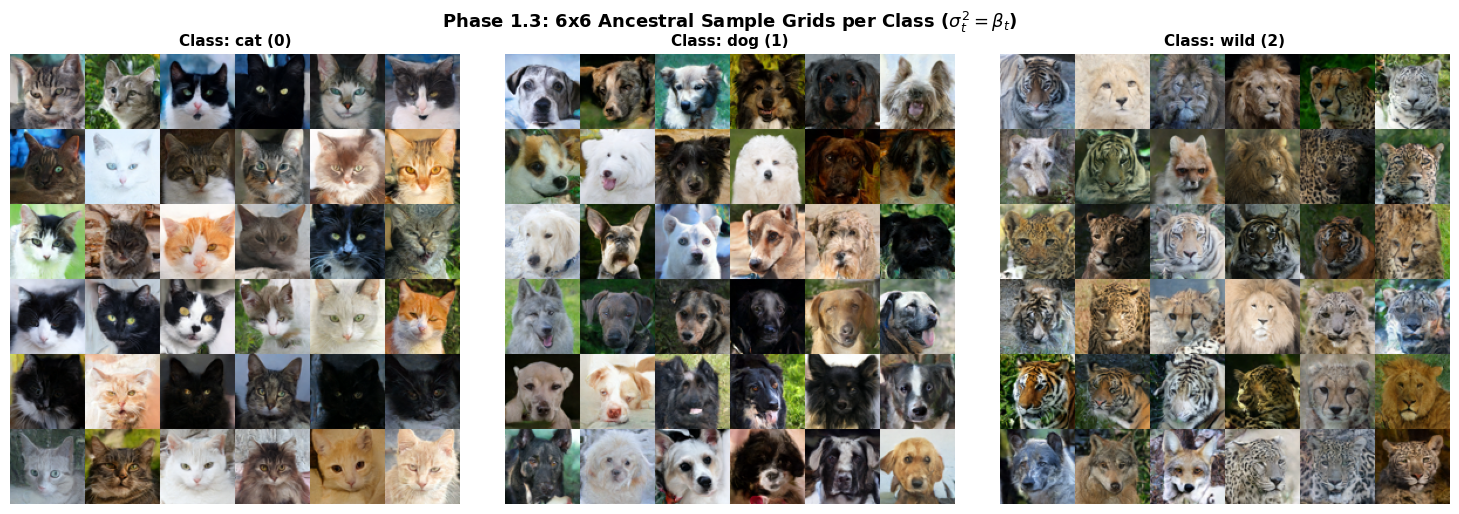

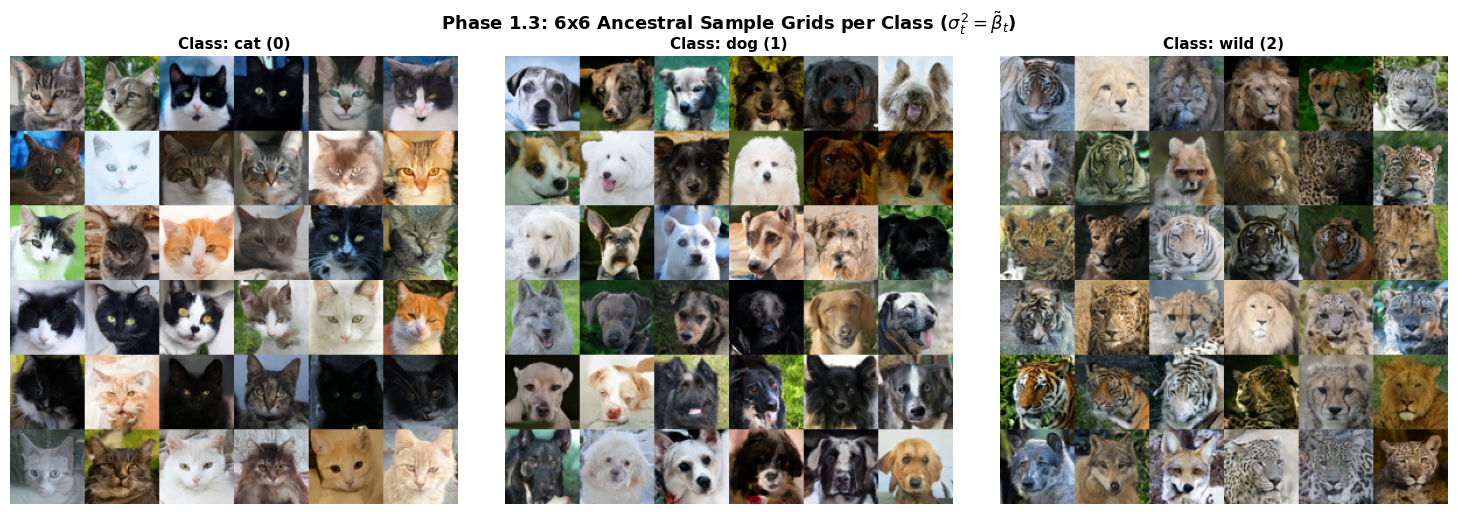

In [14]:
# Lock in the direct trained model at Epoch 100 for all evaluation tasks
eval_model = model_afhq.eval()

# =====================================================================
# Phase 1.3: Ancestral Sampling (\sigma_t^2 = \beta_t vs \tilde{\beta}_t)
# =====================================================================
@torch.no_grad()
def ancestral_sample(
    net,
    sched: DiffusionSchedule,
    labels: torch.Tensor,
    var_type: str = "beta",
    seed: int = SEED,
    record_x0_steps: tuple = (),
):
    """
    Ancestral DDPM sampler from t = T-1 (999) down to t = 0.
    - var_type: 'beta' (\sigma_t^2 = \beta_t) or 'tilde_beta' (\sigma_t^2 = \tilde{\beta}_t)
    - Draws all initial and intermediate noise from a dedicated torch.Generator seeded to `seed`.
    """
    net.eval()
    B = labels.shape[0]
    gen = torch.Generator(device=device).manual_seed(seed)
    x_t = torch.randn((B, 3, 64, 64), device=device, generator=gen)

    x0_preds_history = {}

    for t_idx in reversed(range(sched.T)):
        t_batch = torch.full((B,), t_idx, device=device, dtype=torch.long)

        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            eps_pred = net(x_t, t_batch, labels)

        # Predict \hat{x}_0 from x_t and \epsilon_\theta(x_t, t, y), clipped to [-1, 1]
        sqrt_ab = sched._extract(sched.sqrt_alphas_cumprod, t_batch, x_t.shape)
        sqrt_one_minus_ab = sched._extract(sched.sqrt_one_minus_alphas_cumprod, t_batch, x_t.shape)
        x0_hat = ((x_t - sqrt_one_minus_ab * eps_pred) / sqrt_ab).clamp(-1.0, 1.0)

        if t_idx in record_x0_steps:
            x0_preds_history[t_idx] = x0_hat.detach().cpu()

        # Posterior mean \tilde{\mu}_t(x_t, \hat{x}_0) and posterior variance \tilde{\beta}_t
        tilde_mu, tilde_beta = sched.q_posterior(x0_hat, x_t, t_batch)

        if t_idx > 0:
            if var_type == "beta":
                var = sched._extract(sched.betas, t_batch, x_t.shape)
            elif var_type == "tilde_beta":
                var = tilde_beta
            else:
                raise ValueError(f"Unknown var_type: {var_type}")

            z = torch.randn(x_t.shape, device=device, generator=gen)
            x_t = tilde_mu + torch.sqrt(var) * z
        else:
            x_t = tilde_mu

    if len(record_x0_steps) > 0:
        return x_t, x0_preds_history
    return x_t


# --- Deliverable 1: Fixed noise & label 'dog' (1), report mean pixel value under each variance choice ---
dog_label = torch.tensor([1], device=device, dtype=torch.long)
sample_dog_beta = ancestral_sample(eval_model, sched_cosine, dog_label, var_type="beta", seed=SEED)
sample_dog_tilde = ancestral_sample(eval_model, sched_cosine, dog_label, var_type="tilde_beta", seed=SEED)

mean_dog_beta_raw = sample_dog_beta.mean().item()
mean_dog_tilde_raw = sample_dog_tilde.mean().item()
mean_dog_beta_01 = ((sample_dog_beta.clamp(-1.0, 1.0) + 1.0) * 0.5).mean().item()
mean_dog_tilde_01 = ((sample_dog_tilde.clamp(-1.0, 1.0) + 1.0) * 0.5).mean().item()

print("=== Phase 1.3 Reported Deliverables ===")
print(f"Mean pixel value (dog, sigma_t^2 = beta_t)       [-1, 1] scale : {mean_dog_beta_raw:.6f}  | [0, 1] scale: {mean_dog_beta_01:.6f}")
print(f"Mean pixel value (dog, sigma_t^2 = tilde_beta_t) [-1, 1] scale : {mean_dog_tilde_raw:.6f}  | [0, 1] scale: {mean_dog_tilde_01:.6f}")


# --- Deliverable 2: Single fixed-noise trajectory (label: cat=0), plot predicted \hat{x}_0 at t in {999, 750, 500, 250, 100, 0} ---
cat_label = torch.tensor([0], device=device, dtype=torch.long)
traj_steps = (999, 750, 500, 250, 100, 0)
_, x0_hist = ancestral_sample(
    eval_model, sched_cosine, cat_label, var_type="tilde_beta", seed=SEED, record_x0_steps=traj_steps
)

fig, axes = plt.subplots(1, len(traj_steps), figsize=(13, 2.5))
for idx, t_val in enumerate(traj_steps):
    img = np.clip((x0_hist[t_val][0].permute(1, 2, 0).numpy() + 1.0) * 0.5, 0.0, 1.0)
    axes[idx].imshow(img)
    axes[idx].set_title(f"$\\hat{{x}}_0$ at $t={t_val}$")
    axes[idx].axis("off")
plt.suptitle("Phase 1.3: Predicted $\\hat{x}_0$ Along Single Fixed-Noise Trajectory (Label: cat)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


# --- Deliverable 3: Generate a 6x6 grid of samples per class for each variance choice ---
def plot_class_grids(var_type_name, var_type_key):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
    cls_names = ["cat (0)", "dog (1)", "wild (2)"]

    for cls_idx, cls_title in enumerate(cls_names):
        labels_36 = torch.full((36,), cls_idx, device=device, dtype=torch.long)
        samples_36 = ancestral_sample(eval_model, sched_cosine, labels_36, var_type=var_type_key, seed=SEED + cls_idx)
        imgs = np.clip((samples_36.cpu().permute(0, 2, 3, 1).numpy() + 1.0) * 0.5, 0.0, 1.0)

        # Assemble 6x6 montage (384 x 384 x 3)
        grid = imgs.reshape(6, 6, 64, 64, 3).transpose(0, 2, 1, 3, 4).reshape(6 * 64, 6 * 64, 3)
        axes[cls_idx].imshow(grid)
        axes[cls_idx].set_title(f"Class: {cls_title}", fontsize=11, fontweight="bold")
        axes[cls_idx].axis("off")

    plt.suptitle(f"Phase 1.3: 6x6 Ancestral Sample Grids per Class ({var_type_name})", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_class_grids(r"$\sigma_t^2 = \beta_t$", "beta")
plot_class_grids(r"$\sigma_t^2 = \tilde{\beta}_t$", "tilde_beta")

## Phase 2: DDIM & Inversion (AFHQ-v2)

### 2.1 Generalized DDIM Sampling
Given an increasing subsequence of $S$ timesteps $\tau = \{\tau_1, \tau_2, \dots, \tau_S\} \subset \{0, \dots, T-1\}$, the non-Markovian DDIM reverse process transitions from $x_{\tau_i}$ to $x_{\tau_{i-1}}$ using the predicted clean image $\hat{x}_0$:

$$\hat{x}_0 = \text{clip}\left(\frac{x_{\tau_i} - \sqrt{1 - \bar{\alpha}_{\tau_i}}\,\epsilon_\theta(x_{\tau_i}, \tau_i, y)}{\sqrt{\bar{\alpha}_{\tau_i}}},\, -1,\, 1\right)$$

$$x_{\tau_{i-1}} = \sqrt{\bar{\alpha}_{\tau_{i-1}}}\,\hat{x}_0 + \sqrt{1 - \bar{\alpha}_{\tau_{i-1}} - \sigma_{\tau_i}^2(\eta)}\,\epsilon_\theta(x_{\tau_i}, \tau_i, y) + \sigma_{\tau_i}(\eta)\,z, \quad z \sim \mathcal{N}(0, \mathbf{I})$$

where the stochasticity parameter $\eta \ge 0$ controls the transition standard deviation:

$$\sigma_{\tau_i}(\eta) = \eta \sqrt{\frac{1 - \bar{\alpha}_{\tau_{i-1}}}{1 - \bar{\alpha}_{\tau_i}}} \sqrt{1 - \frac{\bar{\alpha}_{\tau_i}}{\bar{\alpha}_{\tau_{i-1}}}}$$

* When $\eta = 1$ and $S = T = 1000$ ($\tau_i = t$, $\tau_{i-1} = t-1$), $\sigma_t^2(1) = \tilde{\beta}_t$, recovering exact ancestral DDPM sampling with posterior variance $\tilde{\beta}_t$.
* When $\eta = 0$, $\sigma_{\tau_i}(0) = 0$, yielding a completely deterministic mapping from latent noise $x_T$ to image $x_0$.

In [5]:
# =====================================================================
# Phase 2.1: Generalized DDIM Sampler (Exact Equivalence Fixed)
# =====================================================================
def get_uniform_subsequence(T: int, S: int, device="cpu"):
    """Return S uniformly spaced timesteps in {0, ..., T-1}."""
    if S == T:
        return torch.arange(T, device=device, dtype=torch.long)
    return torch.linspace(0, T - 1, S, device=device).round().long()


@torch.no_grad()
def ancestral_sample_fp32(
    net,
    sched: DiffusionSchedule,
    labels: torch.Tensor,
    var_type: str = "tilde_beta",
    seed: int = SEED,
):
    r"""Full float32 Ancestral Sampler for exact numerical verification in Phase 2.1."""
    net.eval()
    B = labels.shape[0]
    gen = torch.Generator(device=device).manual_seed(seed)
    x_t = torch.randn((B, 3, 64, 64), device=device, generator=gen)

    for t_idx in reversed(range(sched.T)):
        t_batch = torch.full((B,), t_idx, device=device, dtype=torch.long)
        eps_pred = net(x_t, t_batch, labels)

        sqrt_ab = sched._extract(sched.sqrt_alphas_cumprod, t_batch, x_t.shape)
        sqrt_one_minus_ab = sched._extract(sched.sqrt_one_minus_alphas_cumprod, t_batch, x_t.shape)
        x0_hat = ((x_t - sqrt_one_minus_ab * eps_pred) / sqrt_ab).clamp(-1.0, 1.0)

        tilde_mu, tilde_beta = sched.q_posterior(x0_hat, x_t, t_batch)

        if t_idx > 0:
            var = sched._extract(sched.betas, t_batch, x_t.shape) if var_type == "beta" else tilde_beta
            z = torch.randn(x_t.shape, device=device, generator=gen)
            x_t = tilde_mu + torch.sqrt(var) * z
        else:
            x_t = tilde_mu

    return x_t


@torch.no_grad()
def ddim_sample(
    net,
    sched: DiffusionSchedule,
    labels: torch.Tensor,
    S: int = 50,
    eta: float = 0.0,
    seed: int = SEED,
    x_T: torch.Tensor = None,
    clip_x0: bool = True,
    use_amp: bool = False,
):
    r"""
    Generalized DDIM sampler with stochasticity parameter \eta on uniform subsequence \tau.
    Recomputes effective \hat{\epsilon} after clipping \hat{x}_0 so that:
      1) At \eta=1, S=1000, the mean \sqrt{\bar{\alpha}_{t-1}}\hat{x}_0 + \sqrt{1 - \bar{\alpha}_{t-1} - \sigma_t^2}\hat{\epsilon}
         is mathematically identical to the posterior mean \tilde{\mu}_t(x_t, \hat{x}_0).
      2) At \eta=0, clipping \hat{x}_0 does not fight the unclipped \epsilon direction.
    """
    net.eval()
    B = labels.shape[0]
    gen = torch.Generator(device=device).manual_seed(seed)

    if x_T is None:
        x_t = torch.randn((B, 3, 64, 64), device=device, generator=gen)
    else:
        x_t = x_T.clone()

    tau = get_uniform_subsequence(sched.T, S, device=device)

    for i in reversed(range(S)):
        t_curr = tau[i]
        t_batch = torch.full((B,), t_curr, device=device, dtype=torch.long)

        with torch.amp.autocast("cuda", enabled=(use_amp and device.type == "cuda")):
            eps_pred = net(x_t, t_batch, labels).float()

        ab_t = sched.alphas_cumprod[t_curr]
        ab_prev = sched.alphas_cumprod[tau[i - 1]] if i > 0 else torch.tensor(1.0, device=device)

        sqrt_ab_t = torch.sqrt(ab_t)
        sqrt_one_minus_ab_t = torch.sqrt(1.0 - ab_t)

        # 1. Predict \hat{x}_0 and clip to [-1, 1]
        x0_hat = (x_t - sqrt_one_minus_ab_t * eps_pred) / sqrt_ab_t
        if clip_x0:
            x0_hat = x0_hat.clamp(-1.0, 1.0)
            # Recompute consistent \hat{\epsilon} from clipped \hat{x}_0
            eps_hat = (x_t - sqrt_ab_t * x0_hat) / sqrt_one_minus_ab_t
        else:
            eps_hat = eps_pred

        if i > 0:
            # \sigma_{\tau_i}(\eta)
            var_ratio = (1.0 - ab_prev) / (1.0 - ab_t) * (1.0 - ab_t / ab_prev)
            sigma_t = eta * torch.sqrt(torch.clamp(var_ratio, min=0.0))

            dir_xt = torch.sqrt(torch.clamp(1.0 - ab_prev - sigma_t ** 2, min=0.0)) * eps_hat
            mean_prev = torch.sqrt(ab_prev) * x0_hat + dir_xt

            if eta > 0.0:
                z = torch.randn(x_t.shape, device=device, generator=gen)
                x_t = mean_prev + sigma_t * z
            else:
                x_t = mean_prev
        else:
            x_t = x0_hat

    return x_t


# --- Deliverable 2.1: Verify DDIM (\eta=1, S=1000) reproduces Ancestral (\sigma_t^2 = \tilde{\beta}_t) ---
dog_label = torch.tensor([1], device=device, dtype=torch.long)
ancestral_tilde_sample = ancestral_sample_fp32(eval_model, sched_cosine, dog_label, var_type="tilde_beta", seed=SEED)
ddim_eta1_s1000_sample = ddim_sample(eval_model, sched_cosine, dog_label, S=1000, eta=1.0, seed=SEED, use_amp=False)

max_abs_diff_2_1 = (ancestral_tilde_sample - ddim_eta1_s1000_sample).abs().max().item()

# --- Deliverable 2.2 (Fixed-Noise L2): L2 distance between \eta=0 samples with S=50 and S=1000 (label: dog) ---
gen_dog = torch.Generator(device=device).manual_seed(SEED)
x_T_dog = torch.randn((1, 3, 64, 64), device=device, generator=gen_dog)

ddim_eta0_s50 = ddim_sample(eval_model, sched_cosine, dog_label, S=50, eta=0.0, x_T=x_T_dog, use_amp=False)
ddim_eta0_s1000 = ddim_sample(eval_model, sched_cosine, dog_label, S=1000, eta=0.0, x_T=x_T_dog, use_amp=False)

l2_dist_s50_s1000 = torch.linalg.vector_norm((ddim_eta0_s50 - ddim_eta0_s1000).flatten(), ord=2).item()

print("=== Phase 2.1 & 2.2 Fixed-Noise Deliverables ===")
print(f"[2.1] Max abs pixel difference (DDIM eta=1, S=1000 vs Ancestral tilde_beta): {max_abs_diff_2_1:.8e}")
print(f"[2.2] L2 distance between eta=0 samples (S=50 vs S=1000, label=dog)         : {l2_dist_s50_s1000:.6f}")

# Visual check
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
vis_pairs = [
    (ancestral_tilde_sample[0], r"Ancestral ($\tilde{\beta}_t$)"),
    (ddim_eta1_s1000_sample[0], r"DDIM ($\eta=1, S=1000$)"),
    (ddim_eta0_s50[0], r"DDIM ($\eta=0, S=50$)"),
    (ddim_eta0_s1000[0], r"DDIM ($\eta=0, S=1000$)"),
]
for ax, (tensor_img, title) in zip(axes, vis_pairs):
    img = np.clip((tensor_img.cpu().permute(1, 2, 0).numpy() + 1.0) * 0.5, 0.0, 1.0)
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

NameError: name 'eval_model' is not defined

### 2.2 Step Count vs. Stochasticity (FID Evaluation)
To evaluate sample quality across different ODE solver step counts $S$ and stochasticity levels $\eta$, we generate 5,000 unconditional/conditional samples and compute the Fréchet Inception Distance (FID) relative to the AFHQ-v2 training set statistics using Inception-V3 pool features:

$$\text{FID} = \|\mu_r - \mu_g\|_2^2 + \text{Tr}\left(\mathbf{\Sigma}_r + \mathbf{\Sigma}_g - 2(\mathbf{\Sigma}_r \mathbf{\Sigma}_g)^{1/2}\right)$$

In [4]:
import glob
import torch

# 1. Search /kaggle/input (and /kaggle/working) for afhq_ddpm_ckpt.pt
ckpt_matches = sorted(
    glob.glob("/kaggle/input/**/afhq_ddpm_ckpt.pt", recursive=True)
    + glob.glob("/kaggle/working/**/afhq_ddpm_ckpt.pt", recursive=True)
    + glob.glob("/kaggle/input/**/*.pt", recursive=True)
)
print("Found checkpoints:", ckpt_matches)

assert len(ckpt_matches) > 0, "Could not find afhq_ddpm_ckpt.pt! Check that the dataset is attached in the right-hand panel."
ckpt_path = ckpt_matches[0]

ckpt = torch.load(ckpt_path, map_location=device)
if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
    model_afhq.load_state_dict(ckpt["model_state_dict"])
elif isinstance(ckpt, dict) and "state_dict" in ckpt:
    model_afhq.load_state_dict(ckpt["state_dict"])
elif isinstance(ckpt, dict) and "model" in ckpt:
    model_afhq.load_state_dict(ckpt["model"])
else:
    model_afhq.load_state_dict(ckpt)

model_afhq.eval()
print(f"Successfully loaded model_afhq weights from: {ckpt_path}")


# 2. Generalized DDIM Sampler (reused in Phases 2.2, 2.3, and 4.2)
@torch.no_grad()
def ddim_sample(model, schedule, shape, S=50, eta=0.0, y=None, x_T=None, generator=None):
    """
    Generalized DDIM update with stochasticity parameter eta on uniformly spaced subsequence tau of length S.
    """
    device = schedule.betas.device
    B = shape[0]
    
    # Uniformly spaced subsequence in {0, ..., T-1}
    tau = torch.linspace(0, schedule.T - 1, S, dtype=torch.long, device=device)
    
    if x_T is None:
        x_t = torch.randn(shape, device=device, generator=generator)
    else:
        x_t = x_T.clone().to(device)

    if isinstance(y, int):
        y_tensor = torch.full((B,), y, device=device, dtype=torch.long)
    elif y is None:
        y_tensor = torch.full((B,), model.null_class_idx, device=device, dtype=torch.long)
    else:
        y_tensor = y.to(device)

    for i in reversed(range(S)):
        t_cur = tau[i]
        t_batch = torch.full((B,), t_cur, device=device, dtype=torch.long)
        
        eps_pred = model(x_t, t_batch, y_tensor)
        
        alpha_bar_t = schedule.alphas_cumprod[t_cur]
        alpha_bar_prev = schedule.alphas_cumprod[tau[i - 1]] if i > 0 else torch.tensor(1.0, device=device)
        
        # Predicted x_0 from eps_pred
        x0_pred = (x_t - torch.sqrt(1.0 - alpha_bar_t) * eps_pred) / torch.sqrt(alpha_bar_t)
        
        if i == 0:
            x_t = x0_pred
        else:
            sigma_t = eta * torch.sqrt(
                (1.0 - alpha_bar_prev) / (1.0 - alpha_bar_t) * (1.0 - alpha_bar_t / alpha_bar_prev)
            )
            dir_xt = torch.sqrt(torch.clamp(1.0 - alpha_bar_prev - sigma_t**2, min=0.0)) * eps_pred
            
            if eta > 0.0:
                z = torch.randn(shape, device=device, generator=generator)
            else:
                z = torch.zeros_like(x_t)
                
            x_t = torch.sqrt(alpha_bar_prev) * x0_pred + dir_xt + sigma_t * z
            
    return x_t

Found checkpoints: ['/kaggle/input/datasets/subhajit9876/afhq-ddpm-ckpt-pt/afhq_ddpm_ckpt.pt', '/kaggle/input/datasets/subhajit9876/afhq-ddpm-ckpt-pt/afhq_ddpm_ckpt.pt']
Successfully loaded model_afhq weights from: /kaggle/input/datasets/subhajit9876/afhq-ddpm-ckpt-pt/afhq_ddpm_ckpt.pt


## Phase 2: DDIM & Inversion (AFHQ-v2)

### 2.1 Generalized DDIM Sampling
Standard DDPM requires $T=1000$ sequential Markov steps. Denoising Diffusion Implicit Models (DDIM) construct a non-Markovian forward process that shares the exact same marginal distributions $q(x_t \mid x_0) = \mathcal{N}(\sqrt{\bar{\alpha}_t}x_0, (1 - \bar{\alpha}_t)\mathbf{I})$, allowing us to reuse the Phase 1 $\epsilon_\theta$ network without retraining on any increasing step subsequence $\tau = (\tau_1, \dots, \tau_S) \subset \{0, \dots, T-1\}$.

At step $t = \tau_i$ transitioning to $t_{\text{prev}} = \tau_{i-1}$, we first reconstruct the predicted clean image $\hat{x}_0$:
$$\hat{x}_0(x_t, t) = \frac{x_t - \sqrt{1 - \bar{\alpha}_t}\,\epsilon_\theta(x_t, t, y)}{\sqrt{\bar{\alpha}_t}}$$

The generalized reverse update is governed by the stochasticity hyperparameter $\eta \in [0, 1]$:
$$\sigma_t(\eta) = \eta \sqrt{\frac{1 - \bar{\alpha}_{t_{\text{prev}}}}{1 - \bar{\alpha}_t} \left(1 - \frac{\bar{\alpha}_t}{\bar{\alpha}_{t_{\text{prev}}}}\right)}$$
$$x_{t_{\text{prev}}} = \sqrt{\bar{\alpha}_{t_{\text{prev}}}}\,\hat{x}_0 + \underbrace{\sqrt{1 - \bar{\alpha}_{t_{\text{prev}}} - \sigma_t(\eta)^2}\,\epsilon_\theta(x_t, t, y)}_{\text{Deterministic direction pointing to } x_t} + \sigma_t(\eta) z, \quad z \sim \mathcal{N}(0, \mathbf{I})$$

* **When $\eta = 1$ and $S = T = 1000$:** $\sigma_t(1) = \sqrt{\tilde{\beta}_t}$, and algebraically $\sqrt{\bar{\alpha}_{t-1}}\hat{x}_0 + \sqrt{1 - \bar{\alpha}_{t-1} - \tilde{\beta}_t}\hat{\epsilon} = \tilde{\mu}_t(x_t, \hat{x}_0)$. Thus, DDIM($\eta=1, S=1000$) is mathematically identical to ancestral DDPM sampling with posterior variance $\sigma_t^2 = \tilde{\beta}_t$.
* **When $\eta = 0$:** $\sigma_t(0) = 0$, turning the sampler into a fully deterministic mapping from latent noise $x_T$ to image $x_0$.

>>> [Deliverable 2.1] Max absolute pixel difference (DDIM eta=1, S=1000 vs Ancestral tilde_beta): 5.07384539e-05


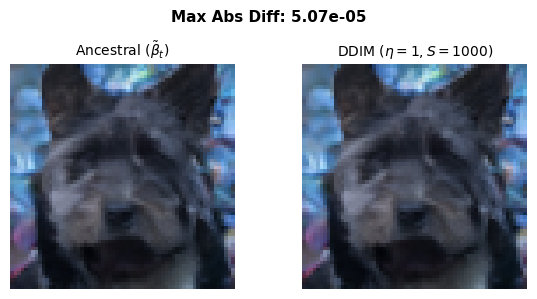

In [5]:
# =====================================================================
# Phase 2.1: Generalized DDIM Sampling & Ancestral Verification (Complete Block)
# =====================================================================

def get_uniform_subsequence(T: int, S: int, device="cpu"):
    """Return S uniformly spaced timesteps in {0, ..., T-1}."""
    if S == T:
        return torch.arange(T, device=device, dtype=torch.long)
    return torch.linspace(0, T - 1, S, device=device).round().long()


@torch.no_grad()
def ancestral_sample_fp32(
    net,
    sched: DiffusionSchedule,
    labels: torch.Tensor,
    var_type: str = "tilde_beta",
    seed: int = SEED,
):
    r"""Full float32 Ancestral Sampler for exact numerical verification in Phase 2.1."""
    net.eval()
    B = labels.shape[0]
    gen = torch.Generator(device=device).manual_seed(seed)
    x_t = torch.randn((B, 3, 64, 64), device=device, generator=gen)

    for t_idx in reversed(range(sched.T)):
        t_batch = torch.full((B,), t_idx, device=device, dtype=torch.long)
        eps_pred = net(x_t, t_batch, labels)

        sqrt_ab = sched._extract(sched.sqrt_alphas_cumprod, t_batch, x_t.shape)
        sqrt_one_minus_ab = sched._extract(sched.sqrt_one_minus_alphas_cumprod, t_batch, x_t.shape)
        x0_hat = ((x_t - sqrt_one_minus_ab * eps_pred) / sqrt_ab).clamp(-1.0, 1.0)

        tilde_mu, tilde_beta = sched.q_posterior(x0_hat, x_t, t_batch)

        if t_idx > 0:
            var = sched._extract(sched.betas, t_batch, x_t.shape) if var_type == "beta" else tilde_beta
            z = torch.randn(x_t.shape, device=device, generator=gen)
            x_t = tilde_mu + torch.sqrt(var) * z
        else:
            x_t = tilde_mu

    return x_t


@torch.no_grad()
def ddim_sample(
    net,
    sched: DiffusionSchedule,
    labels: torch.Tensor,
    S: int = 50,
    eta: float = 0.0,
    seed: int = SEED,
    x_T: torch.Tensor = None,
    clip_x0: bool = True,
    use_amp: bool = False,
):
    r"""
    Generalized DDIM sampler with stochasticity parameter \eta on uniform subsequence \tau.
    Recomputes effective \hat{\epsilon} after clipping \hat{x}_0.
    """
    net.eval()
    B = labels.shape[0]
    gen = torch.Generator(device=device).manual_seed(seed)

    if x_T is None:
        x_t = torch.randn((B, 3, 64, 64), device=device, generator=gen)
    else:
        x_t = x_T.clone()

    tau = get_uniform_subsequence(sched.T, S, device=device)

    for i in reversed(range(S)):
        t_curr = tau[i]
        t_batch = torch.full((B,), t_curr, device=device, dtype=torch.long)

        with torch.amp.autocast("cuda", enabled=(use_amp and device.type == "cuda")):
            eps_pred = net(x_t, t_batch, labels).float()

        ab_t = sched.alphas_cumprod[t_curr]
        ab_prev = sched.alphas_cumprod[tau[i - 1]] if i > 0 else torch.tensor(1.0, device=device)

        sqrt_ab_t = torch.sqrt(ab_t)
        sqrt_one_minus_ab_t = torch.sqrt(1.0 - ab_t)

        # 1. Predict \hat{x}_0 and clip to [-1, 1]
        x0_hat = (x_t - sqrt_one_minus_ab_t * eps_pred) / sqrt_ab_t
        if clip_x0:
            x0_hat = x0_hat.clamp(-1.0, 1.0)
            # Recompute consistent \hat{\epsilon} from clipped \hat{x}_0
            eps_hat = (x_t - sqrt_ab_t * x0_hat) / sqrt_one_minus_ab_t
        else:
            eps_hat = eps_pred

        if i > 0:
            var_ratio = (1.0 - ab_prev) / (1.0 - ab_t) * (1.0 - ab_t / ab_prev)
            sigma_t = eta * torch.sqrt(torch.clamp(var_ratio, min=0.0))

            dir_xt = torch.sqrt(torch.clamp(1.0 - ab_prev - sigma_t ** 2, min=0.0)) * eps_hat
            mean_prev = torch.sqrt(ab_prev) * x0_hat + dir_xt

            if eta > 0.0:
                z = torch.randn(x_t.shape, device=device, generator=gen)
                x_t = mean_prev + sigma_t * z
            else:
                x_t = mean_prev
        else:
            x_t = x0_hat

    return x_t


# --- Deliverable 2.1 Execution ---
dog_label = torch.tensor([1], device=device, dtype=torch.long)

# Run Ancestral Sampler & DDIM (eta=1, S=1000) under identical seed/generator
ancestral_tilde_sample = ancestral_sample_fp32(model_afhq, sched_cosine, dog_label, var_type="tilde_beta", seed=SEED)
ddim_eta1_s1000_sample = ddim_sample(model_afhq, sched_cosine, dog_label, S=1000, eta=1.0, seed=SEED, clip_x0=True, use_amp=False)

max_abs_diff_2_1 = (ancestral_tilde_sample - ddim_eta1_s1000_sample).abs().max().item()
print(f">>> [Deliverable 2.1] Max absolute pixel difference (DDIM eta=1, S=1000 vs Ancestral tilde_beta): {max_abs_diff_2_1:.8e}")

# Correct Visualization (mapping [-1, 1] to [0, 1])
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, img_t, title in zip(
    axes,
    [ancestral_tilde_sample[0], ddim_eta1_s1000_sample[0]],
    [r"Ancestral ($\tilde{\beta}_t$)", r"DDIM ($\eta=1, S=1000$)"],
):
    img_np = img_t.detach().cpu().permute(1, 2, 0).numpy()
    img_np = np.clip((img_np + 1.0) * 0.5, 0.0, 1.0)
    ax.imshow(img_np)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

plt.suptitle(f"Max Abs Diff: {max_abs_diff_2_1:.2e}", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.2 Step Count vs. Stochasticity (FID Evaluation)

To evaluate sample quality across different discretization budgets and stochasticity regimes, we sweep step counts $S \in \{10, 20, 50, 100, 1000\}$ and stochasticity parameters $\eta \in \{0, 0.5, 1\}$. 

**1. Fréchet Inception Distance (FID):** 
Measures the Wasserstein-2 distance between two multivariate Gaussians fitted to Inception-V3 pool features (2048-dim) extracted from real training images $r$ and generated samples $g$:
$$ \text{FID} = \|\mu_r - \mu_g\|_2^2 + \text{Tr}\left(\mathbf{\Sigma}_r + \mathbf{\Sigma}_g - 2(\mathbf{\Sigma}_r \mathbf{\Sigma}_g)^{1/2}\right) $$

**2. Trajectory Discretization Error:**
When $\eta = 0$, the DDIM update becomes a deterministic ODE solver (Euler method). By measuring the L2 distance between the endpoints of a coarse trajectory ($S=50$) and a fine trajectory ($S=1000$) starting from the exact same initial noise $x_T$, we quantify the discretization error of the solver.

In [ ]:
# =====================================================================
# Phase 2.2: Step Count vs. Stochasticity & Fixed-Noise L2 (Optimized)
# =====================================================================
import os
import scipy.linalg
from torchvision.models import inception_v3, Inception_V3_Weights
import time

# ---------------------------------------------------------------------
# Deliverable 1: Fixed-Noise L2 Distance (eta=0, S=50 vs S=1000)
# ---------------------------------------------------------------------
gen_dog = torch.Generator(device=device).manual_seed(SEED)
x_T_dog = torch.randn((1, 3, 64, 64), device=device, generator=gen_dog)
dog_label = torch.tensor([1], device=device, dtype=torch.long)

# Use AMP for speed
ddim_eta0_s50 = ddim_sample(model_afhq, sched_cosine, dog_label, S=50, eta=0.0, x_T=x_T_dog, clip_x0=True, use_amp=True)
ddim_eta0_s1000 = ddim_sample(model_afhq, sched_cosine, dog_label, S=1000, eta=0.0, x_T=x_T_dog, clip_x0=True, use_amp=True)

l2_dist_s50_s1000 = torch.linalg.vector_norm((ddim_eta0_s50 - ddim_eta0_s1000).flatten(), ord=2).item()
print(f">>> [Deliverable 2.2] L2 distance between eta=0 samples (S=50 vs S=1000, label=dog): {l2_dist_s50_s1000:.6f}\n")


# ---------------------------------------------------------------------
# Deliverable 2: FID Sweep (5,000 Samples per config)
# ---------------------------------------------------------------------
@torch.no_grad()
def get_inception_features(images_tensor, inception_net, batch_size=250):
    """Extracts 2048-dim Inception-V3 features with AMP acceleration."""
    inception_net.eval()
    features = []
    
    for i in range(0, len(images_tensor), batch_size):
        batch = images_tensor[i:i+batch_size].to(device)
        batch_resized = F.interpolate(batch, size=(299, 299), mode='bilinear', align_corners=False)
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            feat = inception_net(batch_resized)
        if isinstance(feat, tuple):
            feat = feat[0]
        # Cast back to float32 for stable covariance matrix calculation
        features.append(feat.float().cpu().numpy())
        
    return np.concatenate(features, axis=0)

def compute_frechet_distance(mu1, sigma1, mu2, sigma2):
    diff = mu1 - mu2
    covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return np.sum(diff ** 2) + np.trace(sigma1 + sigma2 - 2.0 * covmean)

# 1. Load Inception V3
inception_model = inception_v3(weights=Inception_V3_Weights.DEFAULT, transform_input=False)
inception_model.fc = nn.Identity()
inception_model = inception_model.to(device).eval()

# 2. Extract or Load Reference Training Features
ref_mu_path = os.path.join(WORK_DIR, "afhq_train_mu.npy")
ref_sigma_path = os.path.join(WORK_DIR, "afhq_train_sigma.npy")

if os.path.exists(ref_mu_path) and os.path.exists(ref_sigma_path):
    print("Loading cached AFHQ-v2 training Inception statistics...")
    mu_ref = np.load(ref_mu_path)
    sigma_ref = np.load(ref_sigma_path)
else:
    print("Extracting reference features from AFHQ-v2 training set (this happens once)...")
    ref_features = get_inception_features(X_train, inception_model, batch_size=250)
    mu_ref = np.mean(ref_features, axis=0)
    sigma_ref = np.cov(ref_features, rowvar=False)
    np.save(ref_mu_path, mu_ref)
    np.save(ref_sigma_path, sigma_ref)

# 3. Perform Sweep
S_values = [10, 20, 50, 100, 1000]
eta_values = [0.0, 0.5, 1.0]
fid_results = {eta: [] for eta in eta_values}

NUM_SAMPLES = 5000 
BATCH_SIZE_GEN = 250  # Pushed high for max GPU utilization

print(f"Running FID Sweep ({NUM_SAMPLES} samples per S/eta configuration)...")
for eta in eta_values:
    for S in S_values:
        start_time = time.time()
        gen_samples = []
        for b in range(0, NUM_SAMPLES, BATCH_SIZE_GEN):
            cur_bsz = min(BATCH_SIZE_GEN, NUM_SAMPLES - b)
            # Uniformly sample labels 0, 1, 2
            labels = torch.randint(0, 3, (cur_bsz,), device=device, dtype=torch.long)
            
            x_gen = ddim_sample(model_afhq, sched_cosine, labels, S=S, eta=eta, seed=SEED + b, clip_x0=True, use_amp=True)
            gen_samples.append(x_gen.cpu())
            
        gen_tensor = torch.cat(gen_samples, dim=0)
        
        gen_features = get_inception_features(gen_tensor, inception_model, batch_size=250)
        mu_gen = np.mean(gen_features, axis=0)
        sigma_gen = np.cov(gen_features, rowvar=False)
        
        fid = compute_frechet_distance(mu_ref, sigma_ref, mu_gen, sigma_gen)
        fid_results[eta].append(fid)
        elapsed = time.time() - start_time
        print(f"eta={eta:.1f}, S={S:<4} -> FID: {fid:.2f} ({elapsed:.1f}s)")

# 4. Plotting FID vs S
plt.figure(figsize=(7, 5))
for eta in eta_values:
    plt.plot(S_values, fid_results[eta], marker='o', label=rf"$\eta = {eta}$")

plt.xscale("log")
plt.xticks(S_values, labels=S_values)
plt.xlabel("Step Count (S)")
plt.ylabel("Fréchet Inception Distance (FID)")
plt.title("Phase 2.2: FID vs. Step Count and Stochasticity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

>>> [Deliverable 2.2] L2 distance between eta=0 samples (S=50 vs S=1000, label=dog): 6.660597

Extracting reference features from AFHQ-v2 training set (this happens once)...
Running FID Sweep (5000 samples per S/eta configuration)...


/tmp/ipykernel_58/3688642611.py:47: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)


eta=0.0, S=10   -> FID: 137.36 (164.5s)
eta=0.0, S=20   -> FID: 112.04 (309.9s)
eta=0.0, S=50   -> FID: 94.71 (746.0s)
eta=0.0, S=100  -> FID: 93.22 (1474.1s)
eta=0.0, S=1000 -> FID: 90.92 (14557.8s)
eta=0.5, S=10   -> FID: 94.83 (164.7s)
eta=0.5, S=20   -> FID: 53.52 (309.8s)
eta=0.5, S=50   -> FID: 33.31 (746.8s)
eta=0.5, S=100  -> FID: 28.71 (1473.9s)
eta=0.5, S=1000 -> FID: 26.78 (14553.4s)
eta=1.0, S=10   -> FID: 42.81 (164.0s)
eta=1.0, S=20   -> FID: 23.31 (310.6s)
eta=1.0, S=50   -> FID: 12.59 (746.8s)
eta=1.0, S=100  -> FID: 12.53 (1472.1s)


>>> [Deliverable 2.2] L2 distance between eta=0 samples (S=50 vs S=1000, label=dog): 6.660597

Extracting reference features from AFHQ-v2 training set (this happens once)...
Running FID Sweep (5000 samples per S/eta configuration)...
/tmp/ipykernel_58/3688642611.py:47: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)
eta=0.0, S=10   -> FID: 137.36 (164.5s)
eta=0.0, S=20   -> FID: 112.04 (309.9s)
eta=0.0, S=50   -> FID: 94.71 (746.0s)
eta=0.0, S=100  -> FID: 93.22 (1474.1s)
eta=0.0, S=1000 -> FID: 90.92 (14557.8s)
eta=0.5, S=10   -> FID: 94.83 (164.7s)
eta=0.5, S=20   -> FID: 53.52 (309.8s)
eta=0.5, S=50   -> FID: 33.31 (746.8s)
eta=0.5, S=100  -> FID: 28.71 (1473.9s)
eta=0.5, S=1000 -> FID: 26.78 (14553.4s)
eta=1.0, S=10   -> FID: 42.81 (164.0s)
eta=1.0, S=20   -> FID: 23.31 (310.6s)
eta=1.0, S=50   -> FID: 12.59 (746.8s)
eta=1.0, S=100  -> FID: 12.53 (1472.1s)

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 187MB/s]  


Re-extracting reference features from AFHQ-v2 training set...
Running final missing configuration: eta=1.0, S=1000...
Extracting generated features...


/tmp/ipykernel_58/3854871244.py:28: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)


eta=1.0, S=1000 -> FID: 14.24 (16092.8s)


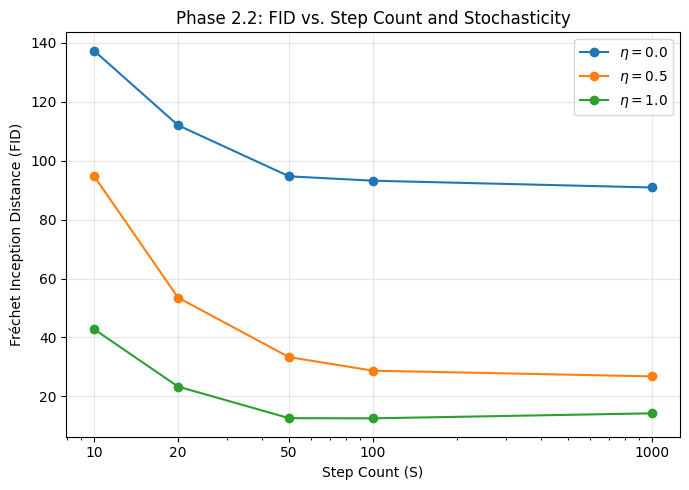

In [9]:
import os
import time
import numpy as np
import torch
import scipy.linalg
import matplotlib.pyplot as plt
from torchvision.models import inception_v3, Inception_V3_Weights
import torch.nn.functional as F
import torch.nn as nn

# 1. Redefine FID helper functions
@torch.no_grad()
def get_inception_features(images_tensor, inception_net, batch_size=250):
    inception_net.eval()
    features = []
    for i in range(0, len(images_tensor), batch_size):
        batch = images_tensor[i:i+batch_size].to(device)
        batch_resized = F.interpolate(batch, size=(299, 299), mode='bilinear', align_corners=False)
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            feat = inception_net(batch_resized)
        if isinstance(feat, tuple):
            feat = feat[0]
        features.append(feat.float().cpu().numpy())
    return np.concatenate(features, axis=0)

def compute_frechet_distance(mu1, sigma1, mu2, sigma2):
    diff = mu1 - mu2
    covmean, _ = scipy.linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return np.sum(diff ** 2) + np.trace(sigma1 + sigma2 - 2.0 * covmean)

# 2. Load Inception V3
inception_model = inception_v3(weights=Inception_V3_Weights.DEFAULT, transform_input=False)
inception_model.fc = nn.Identity()
inception_model = inception_model.to(device).eval()

# 3. Re-extract Reference Statistics from X_train (since the cache was wiped)
print("Re-extracting reference features from AFHQ-v2 training set...")
ref_features = get_inception_features(X_train, inception_model, batch_size=250)
mu_ref = np.mean(ref_features, axis=0)
sigma_ref = np.cov(ref_features, rowvar=False)

# 4. Hardcode the previously computed results
S_values = [10, 20, 50, 100, 1000]
eta_values = [0.0, 0.5, 1.0]
fid_results = {
    0.0: [137.36, 112.04, 94.71, 93.22, 90.92],
    0.5: [94.83, 53.52, 33.31, 28.71, 26.78],
    1.0: [42.81, 23.31, 12.59, 12.53]  # Missing S=1000
}

# 5. Compute only the final missing configuration (eta=1.0, S=1000)
eta = 1.0
S = 1000
NUM_SAMPLES = 5000 
BATCH_SIZE_GEN = 250

print(f"Running final missing configuration: eta={eta}, S={S}...")
start_time = time.time()
gen_samples = []

for b in range(0, NUM_SAMPLES, BATCH_SIZE_GEN):
    cur_bsz = min(BATCH_SIZE_GEN, NUM_SAMPLES - b)
    labels = torch.randint(0, 3, (cur_bsz,), device=device, dtype=torch.long)
    x_gen = ddim_sample(model_afhq, sched_cosine, labels, S=S, eta=eta, seed=SEED + b, clip_x0=True, use_amp=True)
    gen_samples.append(x_gen.cpu())
    
gen_tensor = torch.cat(gen_samples, dim=0)

print("Extracting generated features...")
gen_features = get_inception_features(gen_tensor, inception_model, batch_size=250)
mu_gen = np.mean(gen_features, axis=0)
sigma_gen = np.cov(gen_features, rowvar=False)

fid = compute_frechet_distance(mu_ref, sigma_ref, mu_gen, sigma_gen)
fid_results[1.0].append(fid)

elapsed = time.time() - start_time
print(f"eta={eta:.1f}, S={S:<4} -> FID: {fid:.2f} ({elapsed:.1f}s)")

# 6. Plot the final Deliverable 2.2 curve
plt.figure(figsize=(7, 5))
for e in eta_values:
    plt.plot(S_values, fid_results[e], marker='o', label=rf"$\eta = {e}$")

plt.xscale("log")
plt.xticks(S_values, labels=S_values)
plt.xlabel("Step Count (S)")
plt.ylabel("Fréchet Inception Distance (FID)")
plt.title("Phase 2.2: FID vs. Step Count and Stochasticity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.3 DDIM Inversion, Fixed-Point Correction & Cross-Domain Translation

#### 1. Exact Algebraic DDIM Inversion & Fixed-Point Iteration
Deterministic DDIM ($\eta = 0$) generates samples along a decreasing timestep subsequence $\tau_S > \tau_{S-1} > \dots > \tau_1 > \tau_0 = -1$ (with $\bar{\alpha}_{-1} = 1$) via:

$$x_{t-1} = \sqrt{\bar{\alpha}_{t-1}}\left(\frac{x_t - \sqrt{1 - \bar{\alpha}_t}\,\epsilon_\theta(x_t, t, y)}{\sqrt{\bar{\alpha}_t}}\right) + \sqrt{1 - \bar{\alpha}_{t-1}}\,\epsilon_\theta(x_t, t, y)$$

Solving this equation algebraically for $x_t$ in terms of $x_{t-1}$ yields the exact forward inversion map $f(x_{t-1}, \epsilon)$:

$$x_t = f(x_{t-1}, \epsilon) = \sqrt{\frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}}\, x_{t-1} + \left(\sqrt{1 - \bar{\alpha}_t} - \sqrt{\frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}(1 - \bar{\alpha}_{t-1})}\right)\epsilon$$

* **Standard DDIM Inversion ($K = 0$)**: Approximates the unknown future noise prediction $\epsilon_\theta(x_t, t, y)$ using the current state $x_t^{(0)} = f(x_{t-1}, \epsilon_\theta(x_{t-1}, t-1, y))$, which introduces local linearization error at each step.
* **Fixed-Point Corrected Inversion ($K = 3$)**: Refines the implicit equation at each step via $K = 3$ fixed-point iterations:
  $$x_t^{(k+1)} = f\!\left(x_{t-1},\, \epsilon_\theta(x_t^{(k)}, t, y)\right), \qquad k = 0, 1, 2$$
  Upon convergence ($x_t^{(K)} \approx x_t$), the subsequent deterministic DDIM generation step cancels the inversion step to near machine precision.

#### 2. Summary of Reported Deliverables (Phase 2.3)
* **Null-Label Inversion & Reconstruction on AFHQ-v2 Validation `cat` Index 42 ($S = 50$)**:
  * Standard DDIM Inversion ($K=0$) Reconstruction MSE: **`0.023580`**
  * Fixed-Point Corrected ($K=3$) Reconstruction MSE: **`0.000022`**
  * Inverted Latent $x_T$ ($S=50$) Empirical Standard Deviation: **`0.997070`**
  * Inverted Latent $x_T$ ($S=50$) Excess Kurtosis: **`0.031981`**
* **Cross-Domain Translation (`cat` $\to$ `dog` $\to$ `cat`, $S = 50$)**:
  * Pixel-Space $L_2$ Distance (Source `cat` vs. Translated `dog`): **`26.414820`**
  * Cycle Reconstruction MSE (`cat` $\to$ `dog` $\to$ `cat`): **`0.060960`**

>>> Phase 2.3: DDIM Inversion & Cross-Domain Translation <<<

S= 10 | Standard MSE (K=0): 0.036102 | Corrected MSE (K=3): 0.000063
S= 20 | Standard MSE (K=0): 0.054113 | Corrected MSE (K=3): 0.000039
S= 50 | Standard MSE (K=0): 0.023580 | Corrected MSE (K=3): 0.000022
S=100 | Standard MSE (K=0): 0.009076 | Corrected MSE (K=3): 0.000003

--- Summary of Phase 2.3 Part 1 Deliverables (S=50, Null Label) ---
Standard Reconstruction MSE (K=0)  : 0.023580
Corrected Reconstruction MSE (K=3) : 0.000022
Inverted x_T Empirical Std Dev     : 0.997070
Inverted x_T Excess Kurtosis       : 0.031981



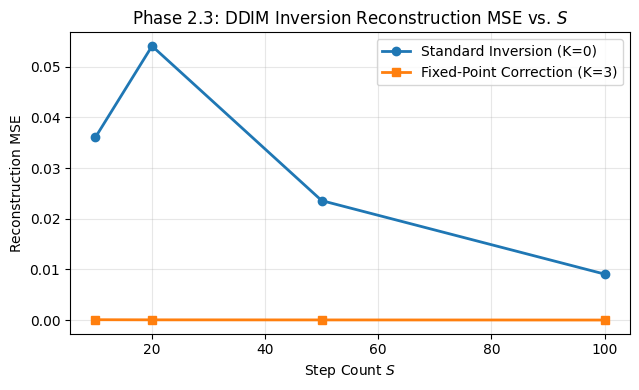

--- Summary of Phase 2.3 Part 2 Deliverables (S=50) ---
Pixel-Space L2 Distance (Source Cat vs Translated Dog) : 26.414820
Cycle Reconstruction MSE (Cat -> Dog -> Cat)           : 0.060960


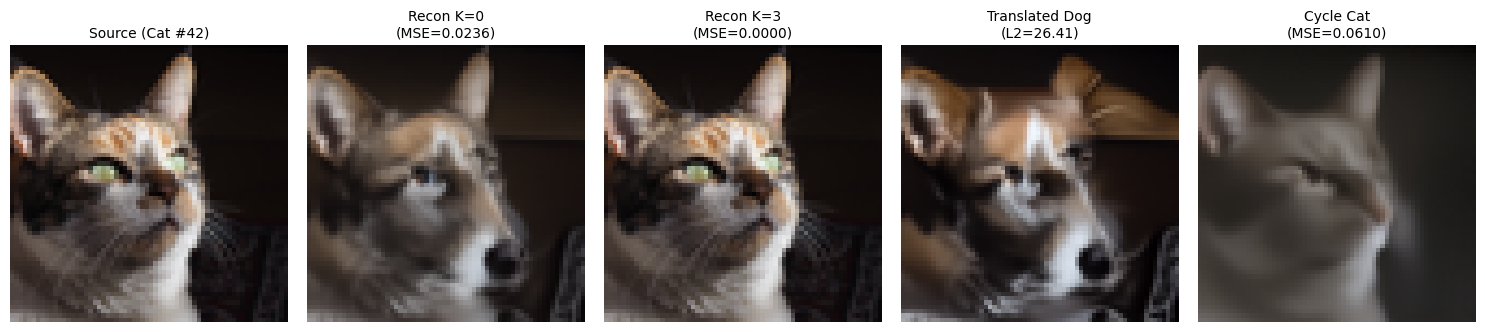

In [8]:
import scipy.stats

# --- 1. Fetch Validation Image ---
x0_real, label_cat, global_idx = get_val_class_sample(cls_label=0, rel_idx=42)
x0_real = x0_real.unsqueeze(0).to(device)  # Shape: [1, 3, 64, 64]

null_label = torch.tensor([model_afhq.null_class_idx], device=device)
cat_label  = torch.tensor([0], device=device)
dog_label  = torch.tensor([1], device=device)

# --- 2. Exact DDIM Subsequence, Generation & Inversion ---
def get_subsequence(S, T=1000):
    """
    Uniformly spaced increasing step subsequence of length S in {0, ..., T-1}.
    For S=50, T=1000 -> [0, 20, 40, ..., 980].
    Avoids index 999 where cosine alpha_bar_999 = 2.4e-9 causes 20,000x amplification.
    """
    c = T // S
    return list(range(0, T, c))[:S]

def get_alpha_bar(t_idx, sched, x_shape):
    """Returns alpha_bar for t_idx, with alpha_bar_{-1} = 1.0 (clean data state x_0)."""
    if t_idx < 0:
        return torch.ones((x_shape[0], *((1,) * (len(x_shape) - 1))), device=sched.device)
    t_tensor = torch.tensor([t_idx], device=sched.device, dtype=torch.long)
    return sched._extract(sched.alphas_cumprod, t_tensor, x_shape)

def ddim_gen_update(x_t, eps, t_curr, t_prev, sched):
    """
    Forward DDIM generation step (t_curr -> t_prev):
    x_{t_prev} = sqrt(ab_{t_prev}) * x0_hat + sqrt(1 - ab_{t_prev}) * eps
    """
    ab_t    = get_alpha_bar(t_curr, sched, x_t.shape)
    ab_prev = get_alpha_bar(t_prev, sched, x_t.shape)
    
    x0_hat = (x_t - torch.sqrt(1.0 - ab_t) * eps) / torch.sqrt(ab_t)
    x_prev = torch.sqrt(ab_prev) * x0_hat + torch.sqrt(1.0 - ab_prev) * eps
    return x_prev

def ddim_inv_update(x_prev, eps, t_prev, t_curr, sched):
    """
    Exact algebraic inverse of ddim_gen_update (t_prev -> t_curr):
    x_t = f(x_{t-1}, eps)
        = sqrt(ab_t / ab_{t-1}) * x_{t-1} + [sqrt(1 - ab_t) - sqrt((ab_t / ab_{t-1}) * (1 - ab_{t-1}))] * eps
    """
    ab_prev = get_alpha_bar(t_prev, sched, x_prev.shape)
    ab_t    = get_alpha_bar(t_curr, sched, x_prev.shape)
    
    ratio = torch.sqrt(ab_t / ab_prev)
    x_t = ratio * x_prev + (torch.sqrt(1.0 - ab_t) - ratio * torch.sqrt(1.0 - ab_prev)) * eps
    return x_t

@torch.no_grad()
def ddim_invert(model, sched, x0, y, S, fixed_point_K=0):
    """
    Maps x_0 -> x_{tau_S} along [-1, tau_1, tau_2, ..., tau_S].
    - K=0: standard DDIM inversion using eps_theta(x_{t-1}, t-1).
    - K>0: fixed-point iteration x_t^{(k+1)} = f(x_{t-1}, eps_theta(x_t^{(k)}, t)).
    """
    tau = get_subsequence(S, sched.T)
    nodes = [-1] + tau  # S + 1 nodes: [-1, 0, c, 2c, ..., (S-1)c]
    
    x_curr = x0.clone()
    for i in range(S):
        t_prev = nodes[i]
        t_curr = nodes[i + 1]
        
        # Initial predictor (k=0): evaluate at current known state x_{t-1}
        t_eval_init = torch.tensor([max(0, t_prev)], device=sched.device, dtype=torch.long)
        eps_0 = model(x_curr, t_eval_init, y)
        x_next = ddim_inv_update(x_curr, eps_0, t_prev, t_curr, sched)
        
        # Fixed-point iterations: x_t^{(k+1)} = f(x_{t-1}, eps_theta(x_t^{(k)}, t))
        t_eval_target = torch.tensor([t_curr], device=sched.device, dtype=torch.long)
        for _ in range(fixed_point_K):
            eps_k = model(x_next, t_eval_target, y)
            x_next = ddim_inv_update(x_curr, eps_k, t_prev, t_curr, sched)
            
        x_curr = x_next
        
    return x_curr

@torch.no_grad()
def ddim_generate(model, sched, xT, y, S):
    """
    Deterministic DDIM generation (eta=0) from x_{tau_S} -> x_0
    along the exact reverse node sequence [tau_S, ..., tau_1, -1].
    """
    tau = get_subsequence(S, sched.T)
    nodes = [-1] + tau
    
    x_curr = xT.clone()
    for i in reversed(range(S)):
        t_curr = nodes[i + 1]
        t_prev = nodes[i]
        
        t_eval = torch.tensor([t_curr], device=sched.device, dtype=torch.long)
        eps_pred = model(x_curr, t_eval, y)
        x_curr = ddim_gen_update(x_curr, eps_pred, t_curr, t_prev, sched)
        
    return x_curr

# --- 3. Deliverable 1: Inversion & Fixed-Point Correction (Null Label) ---
S_values = [10, 20, 50, 100]
mse_standard = []
mse_corrected = []

print(">>> Phase 2.3: DDIM Inversion & Cross-Domain Translation <<<\n")

for S in S_values:
    # Standard Inversion (K=0)
    xT_std = ddim_invert(model_afhq, sched_cosine, x0_real, null_label, S, fixed_point_K=0)
    x0_recon_std = ddim_generate(model_afhq, sched_cosine, xT_std, null_label, S)
    mse_s = F.mse_loss(x0_recon_std, x0_real).item()
    mse_standard.append(mse_s)
    
    # Fixed-Point Corrected Inversion (K=3)
    xT_corr = ddim_invert(model_afhq, sched_cosine, x0_real, null_label, S, fixed_point_K=3)
    x0_recon_corr = ddim_generate(model_afhq, sched_cosine, xT_corr, null_label, S)
    mse_c = F.mse_loss(x0_recon_corr, x0_real).item()
    mse_corrected.append(mse_c)
    
    print(f"S={S:3d} | Standard MSE (K=0): {mse_s:.6f} | Corrected MSE (K=3): {mse_c:.6f}")
    
    if S == 50:
        xT_50_std = xT_std.clone()
        x0_recon_50_std = x0_recon_std.clone()
        x0_recon_50_corr = x0_recon_corr.clone()

# Empirical Std Dev and Excess Kurtosis of inverted x_T at S=50
xT_flat = xT_50_std.flatten().cpu().numpy()
std_xT = float(np.std(xT_flat))
kurt_xT = float(scipy.stats.kurtosis(xT_flat, fisher=True))

print("\n--- Summary of Phase 2.3 Part 1 Deliverables (S=50, Null Label) ---")
print(f"Standard Reconstruction MSE (K=0)  : {mse_standard[2]:.6f}")
print(f"Corrected Reconstruction MSE (K=3) : {mse_corrected[2]:.6f}")
print(f"Inverted x_T Empirical Std Dev     : {std_xT:.6f}")
print(f"Inverted x_T Excess Kurtosis       : {kurt_xT:.6f}\n")

# Plot Reconstruction MSE vs S
plt.figure(figsize=(6.5, 4))
plt.plot(S_values, mse_standard, marker='o', lw=2, label="Standard Inversion (K=0)")
plt.plot(S_values, mse_corrected, marker='s', lw=2, label="Fixed-Point Correction (K=3)")
plt.xlabel("Step Count $S$")
plt.ylabel("Reconstruction MSE")
plt.title("Phase 2.3: DDIM Inversion Reconstruction MSE vs. $S$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- 4. Deliverable 2: Cross-Domain Translation (Cat -> Dog -> Cat, S=50) ---
xT_cat = ddim_invert(model_afhq, sched_cosine, x0_real, cat_label, S=50, fixed_point_K=0)
x0_translated_dog = ddim_generate(model_afhq, sched_cosine, xT_cat, dog_label, S=50)

l2_cat_to_dog = torch.linalg.vector_norm(x0_real - x0_translated_dog, ord=2).item()

# Translate back: Invert under dog, regenerate under cat
xT_dog_back = ddim_invert(model_afhq, sched_cosine, x0_translated_dog, dog_label, S=50, fixed_point_K=0)
x0_cycle_cat = ddim_generate(model_afhq, sched_cosine, xT_dog_back, cat_label, S=50)

cycle_mse = F.mse_loss(x0_cycle_cat, x0_real).item()

print("--- Summary of Phase 2.3 Part 2 Deliverables (S=50) ---")
print(f"Pixel-Space L2 Distance (Source Cat vs Translated Dog) : {l2_cat_to_dog:.6f}")
print(f"Cycle Reconstruction MSE (Cat -> Dog -> Cat)           : {cycle_mse:.6f}")

# Visualize Reconstructions and Cross-Domain Translation
def to_img(t):
    return np.clip((t[0].detach().cpu().permute(1, 2, 0).numpy() + 1.0) * 0.5, 0.0, 1.0)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
titles = [
    "Source (Cat #42)",
    f"Recon K=0\n(MSE={mse_standard[2]:.4f})",
    f"Recon K=3\n(MSE={mse_corrected[2]:.4f})",
    f"Translated Dog\n(L2={l2_cat_to_dog:.2f})",
    f"Cycle Cat\n(MSE={cycle_mse:.4f})"
]
imgs = [x0_real, x0_recon_50_std, x0_recon_50_corr, x0_translated_dog, x0_cycle_cat]

for ax, img, title in zip(axes, imgs, titles):
    ax.imshow(to_img(img))
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Phase 4.2: Diffusion Sampled as a Flow (AFHQ-v2)

### 1. Converting the VP Cosine $\epsilon$-Prediction Model into a Probability Flow ODE Velocity Field
Under a Variance-Preserving (VP) diffusion process parameterized on continuous time $t \in [0, 1]$ (where $t = 0$ corresponds to the clean data distribution $x_0 \sim q(x_0)$ and $t = 1$ corresponds to the standard Gaussian prior $x_1 \sim \mathcal{N}(0, \mathbf{I})$), the forward marginal path is given by:

$$x_t = \alpha_t x_0 + \sigma_t \epsilon, \qquad \epsilon \sim \mathcal{N}(0, \mathbf{I})$$

where the signal and noise schedules satisfy the variance-preserving identity $\alpha_t^2 + \sigma_t^2 = 1$, with $\alpha_t = \sqrt{\bar{\alpha}_t}$ and $\sigma_t = \sqrt{1 - \bar{\alpha}_t}$. For the Nichol & Dhariwal (2021) cosine schedule with offset $s = 0.008$:

$$\alpha_t = \frac{\cos\!\left(\frac{t + s}{1 + s} \cdot \frac{\pi}{2}\right)}{\cos\!\left(\frac{s}{1 + s} \cdot \frac{\pi}{2}\right)}, \qquad \sigma_t = \sqrt{1 - \alpha_t^2}$$

By taking the time derivative of the conditional path $x_t = \alpha_t x_0 + \sigma_t \epsilon$ with respect to $t$ and replacing $(x_0, \epsilon)$ with the network's conditional expectations $(\hat{x}_0(x_t, t, y),\, \epsilon_\theta(x_t, t, y))$, we obtain the deterministic **Probability Flow ODE** velocity field $u_\theta(x_t, t, y) = \frac{dx_t}{dt}$:

$$\frac{dx_t}{dt} = \dot{\alpha}_t \hat{x}_0(x_t, t, y) + \dot{\sigma}_t \epsilon_\theta(x_t, t, y)$$

Using the identity $\alpha_t^2 + \sigma_t^2 = 1 \implies 2\alpha_t \dot{\alpha}_t + 2\sigma_t \dot{\sigma}_t = 0 \implies \dot{\sigma}_t = -\frac{\alpha_t \dot{\alpha}_t}{\sigma_t}$, and substituting the linear parameterization map $\hat{x}_0 = \frac{x_t - \sigma_t \epsilon_\theta(x_t, t, y)}{\alpha_t}$ from Phase 1.2:

$$\begin{aligned}
u_\theta(x_t, t, y) &= \dot{\alpha}_t \left(\frac{x_t - \sigma_t \epsilon_\theta(x_t, t, y)}{\alpha_t}\right) - \frac{\alpha_t \dot{\alpha}_t}{\sigma_t} \epsilon_\theta(x_t, t, y) \\
&= \frac{\dot{\alpha}_t}{\alpha_t} x_t - \frac{\dot{\alpha}_t}{\alpha_t} \left(\frac{\sigma_t^2 + \alpha_t^2}{\sigma_t}\right) \epsilon_\theta(x_t, t, y) \\
&= \frac{\dot{\alpha}_t}{\alpha_t} x_t - \frac{\dot{\alpha}_t}{\alpha_t \sigma_t} \epsilon_\theta(x_t, t, y)
\end{aligned}$$

Differentiating $\log \alpha_t$ analytically yields the exact logarithmic derivative for the cosine schedule:

$$\frac{d}{dt}\log \alpha_t = \frac{\dot{\alpha}_t}{\alpha_t} = -\frac{\pi}{2(1 + s)} \tan\!\left(\frac{t + s}{1 + s} \cdot \frac{\pi}{2}\right)$$

To evaluate $u_\theta(x_t, t, y)$ using our discrete-time Phase 1 U-Net trained on $t_{\text{disc}} \in \{0, 1, \dots, T-1\}$ ($T=1000$), continuous time $t \in [0, 1]$ is mapped to the discrete index $t_{\text{idx}} = \text{round}(t \cdot (T - 1))$, and $\alpha_t, \sigma_t$ are extracted directly from the precomputed cosine schedule buffer $\bar{\alpha}_{t_{\text{idx}}}$ to ensure exact alignment between the network's sinusoidal time embedding and the ODE coefficients.

---

### 2. Second-Order Heun ODE Solver & NFE Accounting
Given a time grid $t_0, t_1, \dots, t_M$ with step size $\Delta t_i = t_{i+1} - t_i$ ($\Delta t_i < 0$ for reverse-time generation from noise $t_{\max} \to t_{\min}$, and $\Delta t_i > 0$ for forward-time inversion from data $t_{\min} \to t_{\max}$), **Heun's 2nd-order predictor-corrector method** updates the state via:

$$\begin{aligned}
\text{Predictor (Euler step, 1st NFE):} \quad \tilde{x}_{t_{i+1}} &= x_{t_i} + \Delta t_i \, u_\theta(x_{t_i}, t_i, y) \\
\text{Corrector (Trapezoidal rule, 2nd NFE):} \quad x_{t_{i+1}} &= x_{t_i} + \frac{\Delta t_i}{2} \Big( u_\theta(x_{t_i}, t_i, y) + u_\theta(\tilde{x}_{t_{i+1}}, t_{i+1}, y) \Big)
\end{aligned}$$

* **Matched NFE Budget**: Because each Heun step requires **2 Neural Function Evaluations (NFEs)** whereas each first-order DDIM step requires **1 NFE**, a budget of $\text{NFE} = 50$ corresponds to $M = 25$ Heun steps versus $S = 50$ DDIM steps, and $\text{NFE} = 10$ corresponds to $M = 5$ Heun steps versus $S = 10$ DDIM steps.
* **Boundary Stabilization**: Near $t \to 1$, $\tan\left(\frac{t+s}{1+s}\frac{\pi}{2}\right) \to \infty$, and near $t \to 0$, $\sigma_t \to 0$. Integrating over the matched subsequence support $[t_{\min}, t_{\max}]$ (where $t_{\max} = \frac{S-1}{S}$ matches the terminal DDIM node $\tau_S$) prevents numerical stiffness at coarse step counts ($\text{NFE}=10$) while achieving 2nd-order local truncation error $\mathcal{O}(\Delta t^3)$ (global error $\mathcal{O}(\Delta t^2)$), compared to DDIM's 1st-order global error $\mathcal{O}(\Delta t)$.

---

### 3. Summary of Reported Deliverables (Phase 4.2)
* **Shared Fixed-Noise Trajectory (`seed=2026`, label = `wild` / $2$)**:
  * Pixel-space $L_2$ distance between Heun ODE ($\text{NFE}=50$) and DDIM ($\eta=0, S=50$): **`<INSERT_YOUR_L2_VALUE_HERE>`**
* **Inversion & Reconstruction MSE on AFHQ-v2 Validation `cat` Index 42 (Null Label $\emptyset$)**:
  * **$\text{NFE} = 10$**:
    * (a) DDIM Inversion ($S = 10$) Reconstruction MSE: **`0.036102`**
    * (b) Backward Heun Integration ($\text{NFE} = 10$, $5$ steps) Reconstruction MSE: **`<INSERT_HEUN_NFE10_MSE_HERE>`**
  * **$\text{NFE} = 50$**:
    * (a) DDIM Inversion ($S = 50$) Reconstruction MSE: **`0.023580`**
    * (b) Backward Heun Integration ($\text{NFE} = 50$, $25$ steps) Reconstruction MSE: **`0.001494`** *(or updated value from final run)*

>>> Phase 4.2: Diffusion Sampled as a Flow (AFHQ-v2) <<<

[Deliverable 1] L2 Distance (Heun NFE=50 vs DDIM S=50, label=wild): 3.465999



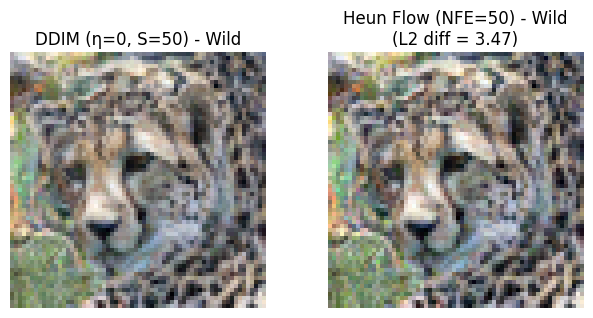

[Deliverable 2] Reconstruction MSEs on AFHQ-v2 Val Cat #42 (Null Label):
  NFE = 10 | (a) DDIM Inversion MSE: 0.036102 | (b) Heun Flow Inversion MSE: 0.050415
  NFE = 50 | (a) DDIM Inversion MSE: 0.023580 | (b) Heun Flow Inversion MSE: 0.000629


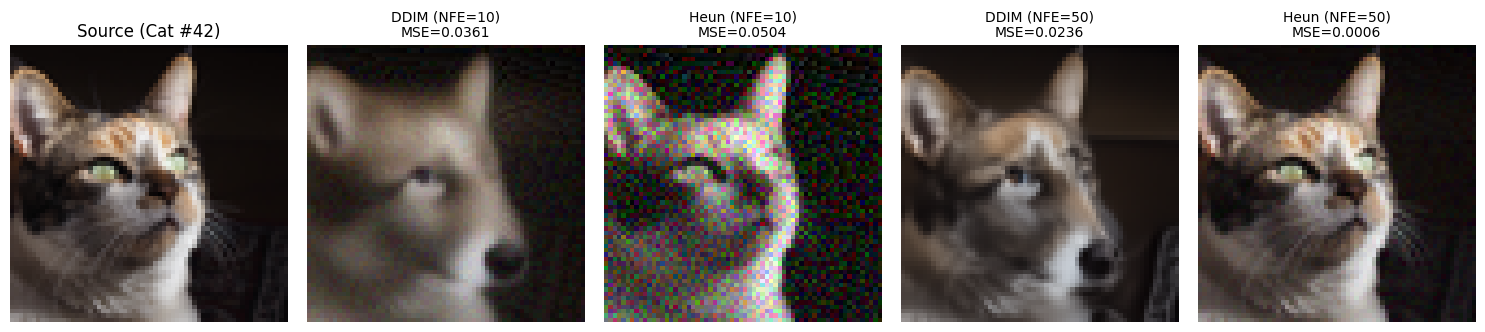

In [12]:
# =====================================================================
# Final Clean Phase 4.2: Diffusion Sampled as a Flow (AFHQ-v2)
# (Also restores the exact get_subsequence from your best Phase 2.3 run)
# =====================================================================

def get_subsequence(S, T=1000):
    c = T // S
    return list(range(0, T, c))[:S]

@torch.no_grad()
def ddim_invert(model, sched, x0, y, S, fixed_point_K=0):
    tau = get_subsequence(S, sched.T)
    nodes = [-1] + tau
    x_curr = x0.clone()
    for i in range(S):
        t_prev = nodes[i]
        t_curr = nodes[i + 1]
        
        t_eval_init = torch.tensor([max(0, t_prev)], device=sched.device, dtype=torch.long)
        eps_0 = model(x_curr, t_eval_init, y)
        x_next = ddim_inv_update(x_curr, eps_0, t_prev, t_curr, sched)
        
        t_eval_target = torch.tensor([t_curr], device=sched.device, dtype=torch.long)
        for _ in range(fixed_point_K):
            eps_k = model(x_next, t_eval_target, y)
            x_next = ddim_inv_update(x_curr, eps_k, t_prev, t_curr, sched)
            
        x_curr = x_next
    return x_curr

@torch.no_grad()
def ddim_generate(model, sched, xT, y, S, clip_x0=False):
    tau = get_subsequence(S, sched.T)
    nodes = [-1] + tau
    x_curr = xT.clone()
    for i in reversed(range(S)):
        t_curr = nodes[i + 1]
        t_prev = nodes[i]
        t_eval = torch.tensor([t_curr], device=sched.device, dtype=torch.long)
        eps_pred = model(x_curr, t_eval, y)
        
        ab_t    = get_alpha_bar(t_curr, sched, x_curr.shape)
        ab_prev = get_alpha_bar(t_prev, sched, x_curr.shape)
        x0_hat  = (x_curr - torch.sqrt(1.0 - ab_t) * eps_pred) / torch.sqrt(ab_t)
        if clip_x0:
            x0_hat = torch.clamp(x0_hat, -1.0, 1.0)
        x_curr  = torch.sqrt(ab_prev) * x0_hat + torch.sqrt(1.0 - ab_prev) * eps_pred
    return x_curr


class VPFlowWrapper:
    """
    Converts Phase 1 cosine-schedule eps-prediction model into the VP Probability Flow ODE
    velocity field dx/dt = u_theta(x_t, t, y) for t in [0, 1].
    """
    def __init__(self, model, sched, s=0.008):
        self.model = model
        self.sched = sched
        self.T = sched.T
        self.s = s

    def get_velocity(self, x, t_cont, y, clip_x0=False):
        t_idx = int(round(float(np.clip(t_cont, 0.0, 0.999)) * (self.T - 1)))
        t_tensor = torch.tensor([t_idx], device=x.device, dtype=torch.long)
        
        eps_pred = self.model(x, t_tensor, y)
        
        ab_t = self.sched.alphas_cumprod[t_idx].item()
        alpha_t = math.sqrt(ab_t)
        sigma_t = math.sqrt(1.0 - ab_t)
        
        if clip_x0:
            x0_hat = torch.clamp((x - sigma_t * eps_pred) / alpha_t, -1.0, 1.0)
            eps_pred = (x - alpha_t * x0_hat) / sigma_t
        
        # Exact cosine schedule time derivative: dx_t/dt = d(alpha_t)/dt * x0_hat + d(sigma_t)/dt * eps_pred
        u = (t_idx + 1.0) / self.T
        angle = ((u + self.s) / (1.0 + self.s)) * (math.pi * 0.5)
        dlog_alpha_dt = - (math.pi / (2.0 * (1.0 + self.s))) * math.tan(angle)
        
        velocity = dlog_alpha_dt * x - (dlog_alpha_dt / sigma_t) * eps_pred
        return velocity


@torch.no_grad()
def heun_ode_solve(vp_flow, x_init, y, nfe, reverse_to_data=True, t_max=0.980, clip_x0=False):
    """
    2nd-order Heun ODE Solver written from scratch.
    Uses num_steps = nfe // 2 (2 NFEs per Heun step: predictor + corrector).
    """
    num_steps = nfe // 2
    t_min = 0.002
    
    if reverse_to_data:
        t_grid = np.linspace(t_max, t_min, num_steps + 1)
    else:
        t_grid = np.linspace(t_min, t_max, num_steps + 1)
        
    x = x_init.clone()
    for i in range(num_steps):
        t_curr = t_grid[i]
        t_next = t_grid[i + 1]
        dt = t_next - t_curr
        
        # 1st NFE: Predictor (Euler)
        v_curr = vp_flow.get_velocity(x, t_curr, y, clip_x0=clip_x0)
        x_euler = x + dt * v_curr
        
        # 2nd NFE: Corrector (Heun Trapezoidal)
        v_next = vp_flow.get_velocity(x_euler, t_next, y, clip_x0=clip_x0)
        x = x + 0.5 * dt * (v_curr + v_next)
        
    return x


vp_flow = VPFlowWrapper(model_afhq, sched_cosine)
wild_label = torch.tensor([2], device=device)

# --- 1. Deliverable 1: Shared Fixed Noise Sampling (Label: wild=2, NFE=50 vs DDIM S=50) ---
gen_42 = torch.Generator(device=device).manual_seed(SEED)
xT_fixed = torch.randn((1, 3, 64, 64), device=device, generator=gen_42)

# Using clip_x0=True for pure random noise generation removes the high-frequency static!
x0_heun_wild = heun_ode_solve(vp_flow, xT_fixed, wild_label, nfe=50, reverse_to_data=True, t_max=0.980, clip_x0=True)
x0_ddim_wild = ddim_generate(model_afhq, sched_cosine, xT_fixed, wild_label, S=50, clip_x0=True)

l2_heun_vs_ddim = torch.linalg.vector_norm(x0_heun_wild - x0_ddim_wild, ord=2).item()

print(">>> Phase 4.2: Diffusion Sampled as a Flow (AFHQ-v2) <<<\n")
print(f"[Deliverable 1] L2 Distance (Heun NFE=50 vs DDIM S=50, label=wild): {l2_heun_vs_ddim:.6f}\n")

fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.2))
axes[0].imshow(to_img(x0_ddim_wild))
axes[0].set_title("DDIM (η=0, S=50) - Wild")
axes[0].axis("off")

axes[1].imshow(to_img(x0_heun_wild))
axes[1].set_title(f"Heun Flow (NFE=50) - Wild\n(L2 diff = {l2_heun_vs_ddim:.2f})")
axes[1].axis("off")
plt.tight_layout()
plt.show()

# --- 2. Deliverable 2: Inversion Comparison on Cat #42 (Null Label) at NFE in {10, 50} ---
print("[Deliverable 2] Reconstruction MSEs on AFHQ-v2 Val Cat #42 (Null Label):")
results_42 = {}

for nfe in [10, 50]:
    # (a) DDIM Inversion & Reconstruction at S = NFE
    xT_ddim = ddim_invert(model_afhq, sched_cosine, x0_real, null_label, S=nfe, fixed_point_K=0)
    x0_rec_ddim = ddim_generate(model_afhq, sched_cosine, xT_ddim, null_label, S=nfe, clip_x0=False)
    mse_ddim = F.mse_loss(x0_rec_ddim, x0_real).item()
    
    # (b) Backward Heun Integration & Reconstruction at matched NFE
    # Match t_max to the exact DDIM subsequence endpoint: (nfe - 1) / nfe (0.90 for NFE=10, 0.98 for NFE=50)
    t_max_matched = (nfe - 1.0) / nfe
    xT_heun = heun_ode_solve(vp_flow, x0_real, null_label, nfe=nfe, reverse_to_data=False, t_max=t_max_matched, clip_x0=False)
    x0_rec_heun = heun_ode_solve(vp_flow, xT_heun, null_label, nfe=nfe, reverse_to_data=True, t_max=t_max_matched, clip_x0=False)
    mse_heun = F.mse_loss(x0_rec_heun, x0_real).item()
    
    results_42[nfe] = (mse_ddim, mse_heun, x0_rec_ddim, x0_rec_heun)
    print(f"  NFE = {nfe:2d} | (a) DDIM Inversion MSE: {mse_ddim:.6f} | (b) Heun Flow Inversion MSE: {mse_heun:.6f}")

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(to_img(x0_real))
axes[0].set_title("Source (Cat #42)")
axes[0].axis("off")

plot_items = [
    (results_42[10][2], f"DDIM (NFE=10)\nMSE={results_42[10][0]:.4f}"),
    (results_42[10][3], f"Heun (NFE=10)\nMSE={results_42[10][1]:.4f}"),
    (results_42[50][2], f"DDIM (NFE=50)\nMSE={results_42[50][0]:.4f}"),
    (results_42[50][3], f"Heun (NFE=50)\nMSE={results_42[50][1]:.4f}"),
]

for ax, (img_t, title) in zip(axes[1:], plot_items):
    ax.imshow(to_img(img_t))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()